# Normalizing-Flow Photometric-Redshift Analysis

This notebook contains the DESI/Legacy photo-$z$ workflow used to train and evaluate a conditional normalizing flow, Random Forest (RF), and Quantile Random Forest (QRF), followed by PDF calibration and $N(z)$ reconstruction.

### Workflow
1. Load the training/testing catalogues and build photometric features.
2. Train/load the normalizing flow and generate posterior samples.
3. Train RF/QRF baselines and compare point estimates.
4. Evaluate feature saliency and probabilistic calibration.
5. Reconstruct the full-sample and tomographic $N(z)$ distributions.

> **Reproducibility notes.** The notebook expects the local FITS catalogues `A1_PATCH1_1.fits` ... `A1_PATCH1_30.fits` and `A1_PATCH2_1.fits` ... `A1_PATCH2_30.fits`.  The trained model`normalizing_flow_final5.pt`is also the local file.


## 1. Imports and helper functions
Core dependencies and reusable utilities for the flow, diagnostics, and sky-footprint plots.


In [1]:
import os
from time import time

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pylab as pl
import seaborn as sns

import torch
from torch.utils.data import DataLoader, TensorDataset

import pyro.distributions as dist
import pyro.distributions.transforms as T

from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.table import Table, vstack

from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from quantile_forest import RandomForestQuantileRegressor

from scipy.stats import wasserstein_distance
from scipy.spatial.distance import jensenshannon

from matplotlib.colors import LogNorm
from matplotlib.ticker import AutoMinorLocator, MultipleLocator, FormatStrFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


In [65]:
def plot_loss_train_eval(nll_train, nll_valid,title):
        plt.figure()
        plt.plot(nll_train, label="train")
        plt.plot(nll_valid, label="valid")
        plt.xlabel("Step / 100")
        plt.ylabel("Loss function")
        plt.title(title)
        plt.legend()
        print(np.mean(nll_train[200:250]),np.mean(nll_valid[200:250]))
        #plt.ylim(-5, 1)
        plt.savefig(f"lossfunction.png", format="png")
def train_validate_test_split( condition_data, x_data, itype ):
    split_range =  [ int( np.around( len(condition_data) * np.sum( np.array(split_fraction)[:i] ) ) ) for i
                     in range(len( split_fraction) + 1 ) ]         
    
    data_range = range(split_range[itype],split_range[itype+1])

    x1 = condition_data[data_range]
    x2 = x_data[data_range]
    return x1, x2


def get_mean_min_loglikelihood( dist_x2_given_x1, x1, x2 ):

    #ln_p_x2_given_x1 = dist_x2_given_x1.condition(x1.detach()).log_prob(x2.detach())
    ln_p_x2_given_x1 = dist_x2_given_x1.condition(x1.detach().to(device)).log_prob(x2.detach().to(device))

    loss = -ln_p_x2_given_x1.mean()
    return loss

def model_training(x1_train, x2_train, x1_validate, x2_validate, output_model):
    dist_base = dist.Normal(
        torch.zeros(1).to(device),
        torch.ones(1).to(device)
    )

    Nconditions = x1_train.shape[1]

    x2_transform = torch.nn.ModuleList([
        T.conditional_spline(
            1,
            context_dim=Nconditions,
            hidden_dims=[32, 32, 32],
            bound=6.0
        )
        for _ in range(num_layers)
    ]).to(device)

    dist_x2_given_x1 = dist.ConditionalTransformedDistribution(
        dist_base,
        list(x2_transform)
    )

    modules = x2_transform

    optimizer = torch.optim.Adam(
        modules.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.MultiStepLR(
        optimizer,
        milestones=[change1, change2],
        gamma=0.1
    )

    train_loader = DataLoader(
        TensorDataset(x1_train, x2_train),
        batch_size=batch_size,
        shuffle=True
    )

    nll_train = []
    nll_valid = []

    best_val_loss = float("inf")
    patience_counter = 0
    t_start = time()

    for epoch in range(N_epochs):
        loss_train = []
        loss_valid = []

        for i, (x1_batch, x2_batch) in enumerate(train_loader):
            x1_batch = x1_batch.to(device)
            x2_batch = x2_batch.to(device)

            optimizer.zero_grad()

            loss = get_mean_min_loglikelihood(
                dist_x2_given_x1,
                x1_batch,
                x2_batch
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                modules.parameters(),
                max_norm=10.0
            )

            optimizer.step()
            dist_x2_given_x1.clear_cache()

            loss_train.append(loss.item())

            with torch.no_grad():
                val_loss = get_mean_min_loglikelihood(
                    dist_x2_given_x1,
                    x1_validate.to(device),
                    x2_validate.to(device)
                )

            loss_valid.append(val_loss.item())
            dist_x2_given_x1.clear_cache()

            if i % 100 == 0:
                print(
                    "%.3i \t%.5i/%.5i \t%.2f \t%.6f \t%.6f \t%.2e"
                    % (
                        epoch,
                        i,
                        len(train_loader),
                        (time() - t_start) / 60.0,
                        np.mean(loss_train),
                        np.mean(loss_valid),
                        optimizer.param_groups[0]["lr"]
                    ),
                    flush=True
                )

        scheduler.step()

        mean_train_loss = np.mean(loss_train)
        mean_valid_loss = np.mean(loss_valid)

        nll_train.append(mean_train_loss)
        nll_valid.append(mean_valid_loss)

        if mean_valid_loss < best_val_loss:
            best_val_loss = mean_valid_loss
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience_limit:
            print(
                f"\nEarly stopping at epoch {epoch}.\n"
                f"Best validation loss: {best_val_loss:.6f}"
            )
            break

    # save final model
    torch.save(
        {
            "model_state_dict": modules.state_dict(),
            "num_layers": num_layers,
            "Nconditions": Nconditions,
            "hidden_dims": [32, 32, 32],
            "bound": 6.0
        },
        output_model
    )

    print(f"Final model saved to {output_model}")

    return dist_x2_given_x1, nll_train, nll_valid

def test_sample_dist( x1_test, x2_test, zs, mean, std):
    x2_flow = np.zeros([ len(x2_test), Nsamples ])
    for isample in range(Nsamples):
        x2_flow[:, isample] = dist_x2_given_x1.condition(x1_test.to(device)).sample(torch.Size([len(x2_test)])).squeeze().detach().cpu().numpy()
    
    x2_flow = x2_flow*std + mean 

    z_maxp = np.zeros( [ len(x2_test[:,0]) ] )
    for i in range(len(x2_test)):    
        hist, bin_edges =  np.histogram( x2_flow[i,:], bins=2000, range=(0,2) ) 
        j = np.argmax(hist)
        z_maxp[i] = ( bin_edges[j+1] + bin_edges[j] ) / 2.
    
    z_median = np.median(x2_flow,axis=1)
    z_mean = np.mean(x2_flow,axis=1)

    err_std = np.std( x2_flow, axis=1 )
    err_68halfpc= ( np.percentile( x2_flow, 84, axis=1 ) - np.percentile( x2_flow, 16, axis=1 ) ) / 2 

#return Monte carlo samples,point estimation
    return x2_flow, z_maxp, z_median, z_mean, err_std, err_68halfpc  

def transmission(EBV):
    #Reden curve(DECAM_G,DECAM_R,DECAM_Z,wise_W1,wise_W2)
    Reden_curve=[3.214,2.165,1.211,1.263,1.088]
    G_transimission=10**(-0.4*Reden_curve[0]*EBV)
    R_transimission=10**(-0.4*Reden_curve[1]*EBV)
    Z_transimission=10**(-0.4*Reden_curve[2]*EBV)
    W1_transimission=10**(-0.4*Reden_curve[3]*EBV)
    W2_transimission=10**(-0.4*Reden_curve[4]*EBV)
    return  G_transimission,R_transimission,Z_transimission, W1_transimission,W2_transimission
def load_model(model_path):
    checkpoint = torch.load(
        model_path,
        map_location=device,
        weights_only=False
    )

    Nconditions = checkpoint["Nconditions"]
    num_layers_saved = checkpoint["num_layers"]
    hidden_dims = checkpoint["hidden_dims"]
    bound = checkpoint["bound"]

    dist_base = dist.Normal(
        torch.zeros(1).to(device),
        torch.ones(1).to(device)
    )

    x2_transform = torch.nn.ModuleList([
        T.conditional_spline(
            1,
            context_dim=Nconditions,
            hidden_dims=hidden_dims,
            bound=bound
        )
        for _ in range(num_layers_saved)
    ]).to(device)

    x2_transform.load_state_dict(
        checkpoint["model_state_dict"]
    )

    x2_transform.eval()

    dist_x2_given_x1 = dist.ConditionalTransformedDistribution(
        dist_base,
        list(x2_transform)
    )

    dist_x2_given_x1.clear_cache()

    return dist_x2_given_x1, x2_transform

In [63]:
def add_galactic_plane(ax, ra_center=180):

    # Galactic longitude along the Galactic plane: b = 0 deg
    l = np.linspace(0, 360, 2000)
    b = np.zeros_like(l)

    gal = SkyCoord(
        l=l * u.deg,
        b=b * u.deg,
        frame="galactic"
    )

    # Convert to equatorial coordinates
    eq = gal.icrs

    ra = eq.ra.deg
    dec = eq.dec.deg

    # Same RA transformation as your footprint
    ra_shift = ((ra - ra_center + 180.0) % 360.0) - 180.0

    x = np.radians(ra_shift)
    y = np.radians(dec)

    # Avoid connecting points across the Mollweide boundary
    jumps = np.abs(np.diff(x)) > np.pi

    x_plot = x.copy()
    y_plot = y.copy()

    x_plot[1:][jumps] = np.nan
    y_plot[1:][jumps] = np.nan

    ax.plot(
        x_plot,
        y_plot,
        linestyle="--",
        linewidth=1.0,
        alpha=0.8,
        label="Galactic plane",
        zorder=3
    )
def isotropic_radec(n):
    ra = np.random.uniform(0.0, 360.0, size=n)
    u = np.random.uniform(-1.0, 1.0, size=n)
    dec = np.degrees(np.arcsin(u))
    return ra, dec

def add_plane_enhancement(ra, dec, width_deg=10, strength=3.0, frac=0.3):
    n_extra = int(len(ra) * frac)
    ra_extra = np.random.uniform(0.0, 360.0, size=n_extra)
    dec_extra = np.random.normal(loc=0.0, scale=width_deg/strength, size=n_extra)
    dec_extra = np.clip(dec_extra, -90, 90)
    return np.concatenate([ra, ra_extra]), np.concatenate([dec, dec_extra])

def radec_hist_density(ra_deg, dec_deg, bins=(360, 180)):
    fig = plt.figure(figsize=(8, 5))
    plt.hist2d(ra_deg, dec_deg, bins=bins, range=[[0, 360], [-90, 90]])
    plt.xlabel("Right Ascension (deg)")
    plt.ylabel("Declination (deg)")
    plt.title("RA–Dec Density (2D histogram)")
    plt.colorbar(label="Counts")
    plt.tight_layout()
    return fig
def plot_patch_boundary(ax, ra_min, ra_max, dec_min, dec_max, color='red'):
    # Build rectangle edges
    ra = np.array([ra_min, ra_max, ra_max, ra_min, ra_min])
    dec = np.array([dec_min, dec_min, dec_max, dec_max, dec_min])

    # Wrap RA to [-180, 180]
    ra_wrap = ((ra + 180) % 360) - 180

    # Convert to radians
    ra_rad = -np.radians(ra_wrap)   # flip RA direction
    dec_rad = np.radians(dec)

    boundary=ax.plot(ra_rad, dec_rad, color=color, lw=1.8)
    return boundary
def radec_mollweide_density(ra_deg, dec_deg, nlon=360, nlat=180,ra_center=180):
    lon_edges_deg = np.linspace(-180, 180, nlon + 1)
    lat_edges_deg = np.linspace(-90, 90, nlat + 1)

    # Wrap RA into [-180, 180]
    lon_deg = ((ra_deg + 180.0) % 360.0) - 180.0

    # 2D histogram
    H, lon_e, lat_e = np.histogram2d(
        lon_deg, dec_deg,
        bins=[lon_edges_deg, lat_edges_deg]
    )

    # Convert bin edges to radians for Mollweide
    lon_edges_rad = -np.radians(lon_e)   # flip sign so RA increases to the left
    lat_edges_rad = np.radians(lat_e)

    LON, LAT = np.meshgrid(lon_edges_rad, lat_edges_rad, indexing="ij")

    fig = plt.figure(figsize=(6, 4))
    ax = fig.add_subplot(111, projection="mollweide")

    # Density map
    pcm = ax.pcolormesh(
        LON, LAT, H,
        shading="auto",
        cmap="Reds"
    )

    # Patch boundary: RA in [80, 160], Dec in [-15, 40]
    ra = np.array([80, 160, 160, 80, 80])
    dec = np.array([-15, -15, 40, 40, -15])

    ra_wrap = ((ra + 180.0) % 360.0) - 180.0
    ra_rad = -np.radians(ra_wrap)
    dec_rad = np.radians(dec)

    ax.plot(
    ra_rad,
    dec_rad,
    color="red",
    lw=1,
    zorder=2.5
,label='Patch footprint')
    add_galactic_plane(ax, ra_center=ra_center)
    ax.grid(True, linewidth=0.5, linestyle=":")
    ax.set_title("Training region")
    ax.legend(loc="upper right",fontsize=11)
    cb = fig.colorbar(pcm, ax=ax, shrink=0.7)
    cb.set_label("Counts per bin",fontsize=11)
    tick_pos_deg = np.arange(-150, 180, 30)
    ax.set_xticks(np.radians(tick_pos_deg))

    tick_ra = (ra_center + tick_pos_deg) % 360

    ax.set_xticklabels(
     [rf"${int(x)}^\circ$" for x in tick_ra]
     )
    fig.tight_layout()
# --- Demo with synthetic data ---
def radec_mollweide_density_testing(
    ra_deg, dec_deg,
    nlon=360, nlat=180,
    ra_center=180
):
    # ---------------------------------------------------
    # Shift RA so that ra_center is at the plot centre
    # ---------------------------------------------------
    lon_deg = ((ra_deg - ra_center + 180.0) % 360.0) - 180.0

    lon_edges_deg = np.linspace(-180, 180, nlon + 1)
    lat_edges_deg = np.linspace(-90, 90, nlat + 1)

    # 2D histogram
    H, lon_e, lat_e = np.histogram2d(
        lon_deg,
        dec_deg,
        bins=[lon_edges_deg, lat_edges_deg]
    )

    # RA increases to the left
    lon_edges_rad = np.radians(lon_e)
    lat_edges_rad = np.radians(lat_e)

    LON, LAT = np.meshgrid(
        lon_edges_rad,
        lat_edges_rad,
        indexing="ij"
    )

    fig = plt.figure(figsize=(6, 4))
    ax = fig.add_subplot(111, projection="mollweide")

    pcm = ax.pcolormesh(
        LON,
        LAT,
        H,
        shading="auto",
        cmap="Reds"
    )

    # ---------------------------------------------------
    # Testing footprint: now a SINGLE rectangle
    # RA = 160--240 deg
    # Dec = -15--40 deg
    # ---------------------------------------------------
    ra_patch = np.array([160, 240, 240, 160, 160])
    dec_patch = np.array([-15, -15, 40, 40, -15])

    # Apply exactly the same RA shift
    ra_shift = (
        (ra_patch - ra_center + 180.0) % 360.0
    ) - 180.0

    ra_rad = np.radians(ra_shift)
    dec_rad = np.radians(dec_patch)

    ax.plot(
        ra_rad,
        dec_rad,
        color="red",
        lw=1.2,
        zorder=2.5,
        label="Patch footprint"
    )

    # ---------------------------------------------------
    # Make tick labels show the ORIGINAL RA coordinates
    # ---------------------------------------------------
    tick_pos_deg = np.arange(-150, 180, 30)

    ax.set_xticks(np.radians(tick_pos_deg))

 
    tick_ra = (ra_center + tick_pos_deg) % 360

    ax.set_xticklabels(
        [rf"${int(x)}^\circ$" for x in tick_ra]
    )

    ax.grid(
        True,
        linewidth=0.5,
        linestyle=":",
        alpha=0.5
    )

    ax.set_title(
        "Testing region"
    )
    add_galactic_plane(ax, ra_center=ra_center)
    ax.legend(loc="lower right",fontsize=11)

    cb = fig.colorbar(
        pcm,
        ax=ax,
        shrink=0.7
    )
    cb.set_label("Counts per bin",fontsize=11)

    fig.tight_layout()
    
    return fig, ax


## 2. Configuration
Normalizing-flow hyperparameters, device selection, and the train/validation split.


In [4]:
# device (recommend GPU with cuda) 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Data split. This 90/10 split is inferred from the stored notebook outputs
# (1,150,368 training and 127,819 validation objects).
split_fraction = [0.9, 0.1]

# Normalizing-flow hyperparameters
num_layers = 3
N_epochs = 75
batch_size = 256
Nsamples = 200
steps = 50
lr = 1e-3

# Learning-rate scheduler / early stopping
change1 = 50
change2 = 75
patience_limit = 100


Using device: cuda


## 3. Load catalogues and inspect the footprint
DESI DR1 selection, footprint and examples to check


In [ ]:
#load the DESI DR1 and Legacy DR10 data, about 22 Gbyte.The github do not have this catalogue, so please jump this cell!
test1=fits.open('desi_y1_obs_in_DR10_w_iband.fits')
#selection standard.The data is tremendous, so you can separate it in many patchs and save them
#A1=test1[1].data
A1=test1[1].data[::30]
print(len(A1))
A1=A1[(A1['FLUX_W1']>0)&(A1['FLUX_G']>0)&(A1['FLUX_R']>0)&(A1['FLUX_Z']>0)&(A1['FLUX_W2']>0)&(A1['ZCAT_PRIMARY']==True)&(A1['zwarn']==0)]
print(len(A1))
#SNR >3, if you wamt the samples with higher quality, increase the SNR.
A1=A1[(A1['FLUX_W1']*np.sqrt(A1['FLUX_IVAR_W1'])>3)&(A1['FLUX_G']*np.sqrt(A1['FLUX_IVAR_G'])>3)&(A1['FLUX_R']*np.sqrt(A1['FLUX_IVAR_R'])>3)&(A1['FLUX_Z']*np.sqrt(A1['FLUX_IVAR_Z'])>3)&(A1['FLUX_W2']*np.sqrt(A1['FLUX_IVAR_W2'])>3)]
A1=A1[(A1['FLUX_I']>0)&(A1['FLUX_I']*np.sqrt(A1['FLUX_IVAR_I'])>3)]
print(len(A1))
#select Spec-z<1, you can freely adjust it.
A1=A1[(A1['Z']<1)]
print(len(A1))
#make separations on training data and testing data
A1_PATCH1=A1[(A1['TARGET_RA']>80)&(A1['TARGET_RA']<160)&(A1['TARGET_DEC']>-15)&((A1['TARGET_DEC']<40))]
A1_PATCH2=A1[(A1['TARGET_RA']>160)&(A1['TARGET_RA']<240)&(A1['TARGET_DEC']>-15)&((A1['TARGET_DEC']<40))]
#save the training patch and testing patch
t_patch1 = Table(A1_PATCH1)
t_patch1.write("A1_PATCH1.fits", format="fits", overwrite=True)

t_patch2 = Table(A1_PATCH2)
t_patch2.write("A1_PATCH2.fits", format="fits", overwrite=True)

In [47]:
#examples of small data, uploaded in github. You can check it with these samples with Spec-z<1 or Spec-z>1
training=Table.read('example_training.fits')
testing=Table.read('example_testing.fits')
training_high=Table.read('example_training_high.fits')
testing_high=Table.read('example_testing_high.fits')

In [48]:
#choose the samples Spec-z<1
A1_PATCH2=testing
A1_PATCH1=training

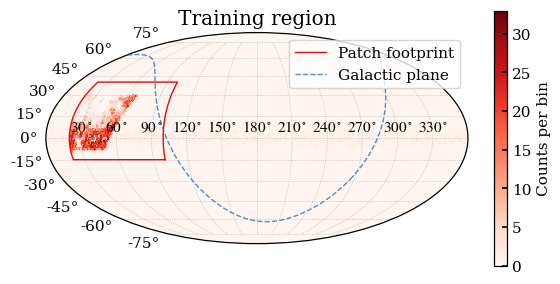

In [49]:
np.random.seed(7)
ra =A1_PATCH1['TARGET_RA'] 
dec = A1_PATCH1['TARGET_DEC'] 
ra, dec = add_plane_enhancement(ra, dec, width_deg=12, strength=3.0, frac=0.25)
#fig1 = radec_hist_density(ra, dec, bins=(360, 180))
radec_mollweide_density(ra, dec, nlon=360, nlat=180)


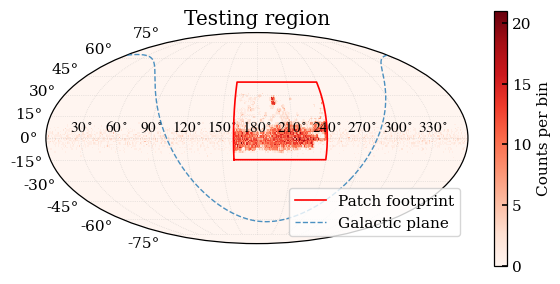

In [50]:
np.random.seed(7)
ra =A1_PATCH2['TARGET_RA'] 
dec = A1_PATCH2['TARGET_DEC'] 
ra, dec = add_plane_enhancement(ra, dec, width_deg=12, strength=3.0, frac=0.25)

#fig1 = radec_hist_density(ra, dec, bins=(360, 180))
fig2 = radec_mollweide_density_testing(ra, dec, nlon=360, nlat=180)

## 4. Build photometric features and split the data
The conditioning vector contains 23 magnitudes, colours, morphology, inverse-variance, and PSF-depth features.


In [51]:
# Milky-Way transmission corrections
trans_patch1 = transmission(A1_PATCH1["EBV"])
trans_patch2 = transmission(A1_PATCH2["EBV"])

# Extinction-corrected magnitudes
m_g_PATCH1 = 22.5 - 2.5 * np.log10(A1_PATCH1["FLUX_G"] / trans_patch1[0])
m_r_PATCH1 = 22.5 - 2.5 * np.log10(A1_PATCH1["FLUX_R"] / trans_patch1[1])
m_z_PATCH1 = 22.5 - 2.5 * np.log10(A1_PATCH1["FLUX_Z"] / trans_patch1[2])
m_w1_PATCH1 = 22.5 - 2.5 * np.log10(A1_PATCH1["FLUX_W1"] / trans_patch1[3])
m_w2_PATCH1 = 22.5 - 2.5 * np.log10(A1_PATCH1["FLUX_W2"] / trans_patch1[4])
m_i_PATCH1 = 22.5 - 2.5 * np.log10(
    A1_PATCH1["FLUX_I"] / A1_PATCH1["MW_TRANSMISSION_I"]
)

m_g_PATCH2 = 22.5 - 2.5 * np.log10(A1_PATCH2["FLUX_G"] / trans_patch2[0])
m_r_PATCH2 = 22.5 - 2.5 * np.log10(A1_PATCH2["FLUX_R"] / trans_patch2[1])
m_z_PATCH2 = 22.5 - 2.5 * np.log10(A1_PATCH2["FLUX_Z"] / trans_patch2[2])
m_w1_PATCH2 = 22.5 - 2.5 * np.log10(A1_PATCH2["FLUX_W1"] / trans_patch2[3])
m_w2_PATCH2 = 22.5 - 2.5 * np.log10(A1_PATCH2["FLUX_W2"] / trans_patch2[4])
m_i_PATCH2 = 22.5 - 2.5 * np.log10(
    A1_PATCH2["FLUX_I"] / A1_PATCH2["MW_TRANSMISSION_I"]
)


In [52]:
# Feature order used by the NF (23 conditioning variables).
FEATURE_NAMES = [
    "g", "r", "i", "z", "W1", "W2",
    "g-r", "r-i", "i-z", "z-W1", "W1-W2",
    "SHAPE_R", "SERSIC",
    "FLUX_IVAR_G", "FLUX_IVAR_R", "FLUX_IVAR_Z", "FLUX_IVAR_I",
    "FLUX_IVAR_W1", "FLUX_IVAR_W2",
    "PSFDEPTH_G", "PSFDEPTH_R", "PSFDEPTH_I", "PSFDEPTH_Z",
]

condition_data_PATCH1 = np.column_stack([
    m_g_PATCH1, m_r_PATCH1, m_i_PATCH1, m_z_PATCH1, m_w1_PATCH1, m_w2_PATCH1,
    m_g_PATCH1 - m_r_PATCH1,
    m_r_PATCH1 - m_i_PATCH1,
    m_i_PATCH1 - m_z_PATCH1,
    m_z_PATCH1 - m_w1_PATCH1,
    m_w1_PATCH1 - m_w2_PATCH1,
    A1_PATCH1["SHAPE_R"], A1_PATCH1["SERSIC"],
    A1_PATCH1["FLUX_IVAR_G"], A1_PATCH1["FLUX_IVAR_R"],
    A1_PATCH1["FLUX_IVAR_Z"], A1_PATCH1["FLUX_IVAR_I"],
    A1_PATCH1["FLUX_IVAR_W1"], A1_PATCH1["FLUX_IVAR_W2"],
    A1_PATCH1["PSFDEPTH_G"], A1_PATCH1["PSFDEPTH_R"],
    A1_PATCH1["PSFDEPTH_I"], A1_PATCH1["PSFDEPTH_Z"],
]).astype(np.float64)

condition_data_PATCH2 = np.column_stack([
    m_g_PATCH2, m_r_PATCH2, m_i_PATCH2, m_z_PATCH2, m_w1_PATCH2, m_w2_PATCH2,
    m_g_PATCH2 - m_r_PATCH2,
    m_r_PATCH2 - m_i_PATCH2,
    m_i_PATCH2 - m_z_PATCH2,
    m_z_PATCH2 - m_w1_PATCH2,
    m_w1_PATCH2 - m_w2_PATCH2,
    A1_PATCH2["SHAPE_R"], A1_PATCH2["SERSIC"],
    A1_PATCH2["FLUX_IVAR_G"], A1_PATCH2["FLUX_IVAR_R"],
    A1_PATCH2["FLUX_IVAR_Z"], A1_PATCH2["FLUX_IVAR_I"],
    A1_PATCH2["FLUX_IVAR_W1"], A1_PATCH2["FLUX_IVAR_W2"],
    A1_PATCH2["PSFDEPTH_G"], A1_PATCH2["PSFDEPTH_R"],
    A1_PATCH2["PSFDEPTH_I"], A1_PATCH2["PSFDEPTH_Z"],
]).astype(np.float64)

assert condition_data_PATCH1.shape[1] == len(FEATURE_NAMES)
assert condition_data_PATCH2.shape[1] == len(FEATURE_NAMES)


In [53]:
x_data_PATCH1=A1_PATCH1['Z']
x_data_PATCH2=A1_PATCH2['Z']

In [54]:
condition_data_PATCH1, x_data_PATCH1 = shuffle(condition_data_PATCH1,x_data_PATCH1, random_state=38)
condition_data_PATCH2, x_data_PATCH2 = shuffle(condition_data_PATCH2,x_data_PATCH2, random_state=38)

In [55]:
x1_train, x2_train = train_validate_test_split( condition_data_PATCH1, x_data_PATCH1, 0 )
x1_validate, x2_validate = train_validate_test_split( condition_data_PATCH1, x_data_PATCH1, 1 )
x1_test, x2_test =condition_data_PATCH2, x_data_PATCH2

mean = np.mean(x2_train)
std = np.std(x2_train)
print(mean)
print(std)

0.3195790122254018
0.29517677215325405


### 4.1 Redshift distributions
Training and testing spectroscopic-redshift distributions, including the low-$z$ boundary near $z=0.006$.


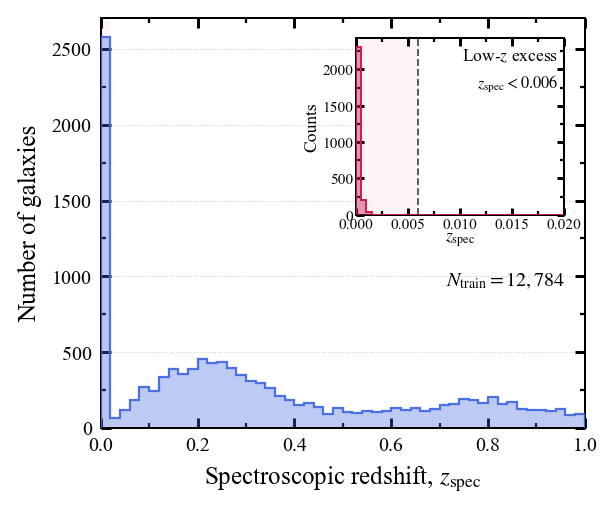

In [56]:

# ============================================================
# MNRAS-like plotting style
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "STIXGeneral",
        "DejaVu Serif",
    ],
    "mathtext.fontset": "stix",

    "font.size": 9,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    "axes.linewidth": 0.8,

    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
})


# ============================================================
# Prepare data
# ============================================================
zs_train_plot = np.asarray(x2_train, dtype=float)

# Remove NaN and infinite values
zs_train_plot = zs_train_plot[
    np.isfinite(zs_train_plot)
]

# Plotting limits
z_min = 0.0
z_max = 1.0

# Low-redshift boundary
z_cut = 0.006

# Maximum redshift displayed in inset
zoom_max = 0.020


# Total number of galaxies
n_train = len(zs_train_plot)

# Number and fraction below z = 0.006
low_mask = zs_train_plot < z_cut

n_low = np.sum(low_mask)
frac_low = n_low / n_train if n_train > 0 else np.nan


# ============================================================
# Histogram bins
# ============================================================

# Main histogram:
# Delta z = 0.02
main_bins = np.linspace(
    z_min,
    z_max,
    51,
)

# Inset:
# Delta z = 0.0005
zoom_bins = np.linspace(
    z_min,
    zoom_max,
    41,
)


# ============================================================
# Create figure
# ============================================================
fig, ax = plt.subplots(
    figsize=(3.32, 2.85),
    dpi=180,
)


# ============================================================
# Main histogram
# ============================================================

# Filled histogram
ax.hist(
    zs_train_plot,
    bins=main_bins,
    histtype="stepfilled",
    color="royalblue",
    edgecolor="royalblue",
    linewidth=0.75,
    alpha=0.35,
    zorder=2,
)

# Clear outline
ax.hist(
    zs_train_plot,
    bins=main_bins,
    histtype="step",
    color="royalblue",
    linewidth=0.90,
    alpha=0.90,
    zorder=3,
)

# Subtle indication of the region enlarged in the inset
ax.axvspan(
    z_min,
    zoom_max,
    color="crimson",
    alpha=0.035,
    linewidth=0,
    zorder=1,
)


# ============================================================
# Main-axis formatting
# ============================================================
ax.set_xlim(z_min, z_max)
ax.set_ylim(bottom=0)

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$"
)

ax.set_ylabel(
    "Number of galaxies"
)

ax.xaxis.set_major_locator(
    MultipleLocator(0.2)
)

ax.xaxis.set_minor_locator(
    MultipleLocator(0.1)
)

ax.yaxis.set_minor_locator(
    AutoMinorLocator(2)
)

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True,
)

# Subtle horizontal grid
ax.grid(
    axis="y",
    which="major",
    color="0.82",
    linewidth=0.45,
    linestyle=":",
    zorder=0,
)

# Total training-set size
ax.text(
    0.96,
    0.36,
    rf"$N_{{\rm train}}={n_train:,}$",
    transform=ax.transAxes,
    ha="right",
    va="center",
    fontsize=8,
)


# ============================================================
# Inset: low-redshift zoom
# ============================================================
axins = inset_axes(
    ax,
    width="43%",
    height="43%",
    loc="upper right",
    borderpad=0.75,
)

# Galaxies within the inset range
z_zoom = zs_train_plot[
    (zs_train_plot >= z_min)
    & (zs_train_plot <= zoom_max)
]

# Galaxies in the boundary-affected region
z_boundary = zs_train_plot[
    (zs_train_plot >= z_min)
    & (zs_train_plot < z_cut)
]


# ------------------------------------------------------------
# Full low-z distribution in blue
# ------------------------------------------------------------
axins.hist(
    z_zoom,
    bins=zoom_bins,
    histtype="stepfilled",
    color="royalblue",
    edgecolor="royalblue",
    linewidth=0.55,
    alpha=0.18,
    zorder=2,
)

axins.hist(
    z_zoom,
    bins=zoom_bins,
    histtype="step",
    color="royalblue",
    linewidth=0.70,
    alpha=0.75,
    zorder=3,
)


# ------------------------------------------------------------
# Highlight z < 0.006 in red
# ------------------------------------------------------------
axins.hist(
    z_boundary,
    bins=zoom_bins,
    histtype="stepfilled",
    color="crimson",
    edgecolor="crimson",
    linewidth=0.60,
    alpha=0.32,
    zorder=4,
)

axins.hist(
    z_boundary,
    bins=zoom_bins,
    histtype="step",
    color="crimson",
    linewidth=0.75,
    alpha=0.90,
    zorder=5,
)

# Light red background for the excluded region
axins.axvspan(
    z_min,
    z_cut,
    color="crimson",
    alpha=0.055,
    linewidth=0,
    zorder=1,
)

# Boundary at z = 0.006
axins.axvline(
    z_cut,
    color="0.25",
    linewidth=0.75,
    linestyle="--",
    alpha=0.90,
    zorder=6,
)


# ============================================================
# Inset formatting
# ============================================================
axins.set_xlim(z_min, zoom_max)
axins.set_ylim(bottom=0)

axins.set_xlabel(
    r"$z_{\rm spec}$",
    fontsize=7,
    labelpad=0,
)

axins.set_ylabel(
    "Counts",
    fontsize=7,
    labelpad=1,
)

# Major ticks: 0.000, 0.005, ..., 0.020
axins.xaxis.set_major_locator(
    MultipleLocator(0.005)
)

axins.xaxis.set_major_formatter(
    FormatStrFormatter("%.3f")
)

axins.xaxis.set_minor_locator(
    MultipleLocator(0.0025)
)

axins.yaxis.set_minor_locator(
    AutoMinorLocator(2)
)

axins.tick_params(
    which="major",
    direction="in",
    top=True,
    right=True,
    labelsize=6.2,
    length=3,
    pad=1,
)

axins.tick_params(
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=1.5,
)


# ============================================================
# Inset annotations
# ============================================================

# Title placed inside the inset
axins.text(
    0.97,
    0.95,
    r"Low-$z$ excess",
    transform=axins.transAxes,
    ha="right",
    va="top",
    fontsize=7.0,
)

# Description of highlighted region
axins.text(
    0.97,
    0.80,
    r"$z_{\rm spec}<0.006$",
    transform=axins.transAxes,
    ha="right",
    va="top",
    fontsize=6.5,
    color="black",
)


# ============================================================
# Final layout
# ============================================================
fig.subplots_adjust(
    left=0.17,
    right=0.98,
    bottom=0.18,
    top=0.98,
)


# ============================================================
# Save
# ============================================================
fig.savefig(
    "DESI_training_redshift_distribution_inset.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "DESI_training_redshift_distribution_inset.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

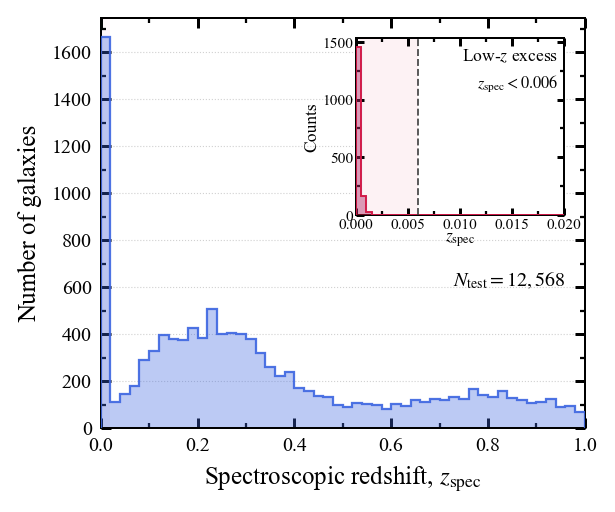

In [57]:

# ============================================================
# MNRAS-like plotting style
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "STIXGeneral",
        "DejaVu Serif",
    ],
    "mathtext.fontset": "stix",

    "font.size": 9,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    "axes.linewidth": 0.8,

    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
})


# ============================================================
# Prepare data
# ============================================================
zs_train_plot = np.asarray(x2_test, dtype=float)

# Remove NaN and infinite values
zs_train_plot = zs_train_plot[
    np.isfinite(zs_train_plot)
]

# Plotting limits
z_min = 0.0
z_max = 1.0

# Low-redshift boundary
z_cut = 0.006

# Maximum redshift displayed in inset
zoom_max = 0.020

# Total number of galaxies
n_train = len(zs_train_plot)

# Number and fraction below z = 0.006
low_mask = zs_train_plot < z_cut

n_low = np.sum(low_mask)
frac_low = n_low / n_train if n_train > 0 else np.nan


# ============================================================
# Histogram bins
# ============================================================

# Main histogram:
# Delta z = 0.02
main_bins = np.linspace(
    z_min,
    z_max,
    51,
)

# Inset:
# Delta z = 0.0005
zoom_bins = np.linspace(
    z_min,
    zoom_max,
    41,
)


# ============================================================
# Create figure
# ============================================================
fig, ax = plt.subplots(
    figsize=(3.32, 2.85),
    dpi=180,
)


# ============================================================
# Main histogram
# ============================================================

# Filled histogram
ax.hist(
    zs_train_plot,
    bins=main_bins,
    histtype="stepfilled",
    color="royalblue",
    edgecolor="royalblue",
    linewidth=0.75,
    alpha=0.35,
    zorder=2,
)

# Clear outline
ax.hist(
    zs_train_plot,
    bins=main_bins,
    histtype="step",
    color="royalblue",
    linewidth=0.90,
    alpha=0.90,
    zorder=3,
)

# Subtle indication of the region enlarged in the inset
ax.axvspan(
    z_min,
    zoom_max,
    color="crimson",
    alpha=0.035,
    linewidth=0,
    zorder=1,
)


# ============================================================
# Main-axis formatting
# ============================================================
ax.set_xlim(z_min, z_max)
ax.set_ylim(bottom=0)

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$"
)

ax.set_ylabel(
    "Number of galaxies"
)

ax.xaxis.set_major_locator(
    MultipleLocator(0.2)
)

ax.xaxis.set_minor_locator(
    MultipleLocator(0.1)
)

ax.yaxis.set_minor_locator(
    AutoMinorLocator(2)
)

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True,
)

# Subtle horizontal grid
ax.grid(
    axis="y",
    which="major",
    color="0.82",
    linewidth=0.45,
    linestyle=":",
    zorder=0,
)

# Total training-set size
ax.text(
    0.96,
    0.36,
    rf"$N_{{\rm test}}={n_train:,}$",
    transform=ax.transAxes,
    ha="right",
    va="center",
    fontsize=8,
)


# ============================================================
# Inset: low-redshift zoom
# ============================================================
axins = inset_axes(
    ax,
    width="43%",
    height="43%",
    loc="upper right",
    borderpad=0.75,
)

# Galaxies within the inset range
z_zoom = zs_train_plot[
    (zs_train_plot >= z_min)
    & (zs_train_plot <= zoom_max)
]

# Galaxies in the boundary-affected region
z_boundary = zs_train_plot[
    (zs_train_plot >= z_min)
    & (zs_train_plot < z_cut)
]


# ------------------------------------------------------------
# Full low-z distribution in blue
# ------------------------------------------------------------
axins.hist(
    z_zoom,
    bins=zoom_bins,
    histtype="stepfilled",
    color="royalblue",
    edgecolor="royalblue",
    linewidth=0.55,
    alpha=0.18,
    zorder=2,
)

axins.hist(
    z_zoom,
    bins=zoom_bins,
    histtype="step",
    color="royalblue",
    linewidth=0.70,
    alpha=0.75,
    zorder=3,
)


# ------------------------------------------------------------
# Highlight z < 0.006 in red
# ------------------------------------------------------------
axins.hist(
    z_boundary,
    bins=zoom_bins,
    histtype="stepfilled",
    color="crimson",
    edgecolor="crimson",
    linewidth=0.60,
    alpha=0.32,
    zorder=4,
)

axins.hist(
    z_boundary,
    bins=zoom_bins,
    histtype="step",
    color="crimson",
    linewidth=0.75,
    alpha=0.90,
    zorder=5,
)

# Light red background for the excluded region
axins.axvspan(
    z_min,
    z_cut,
    color="crimson",
    alpha=0.055,
    linewidth=0,
    zorder=1,
)

# Boundary at z = 0.006
axins.axvline(
    z_cut,
    color="0.25",
    linewidth=0.75,
    linestyle="--",
    alpha=0.90,
    zorder=6,
)


# ============================================================
# Inset formatting
# ============================================================
axins.set_xlim(z_min, zoom_max)
axins.set_ylim(bottom=0)

axins.set_xlabel(
    r"$z_{\rm spec}$",
    fontsize=7,
    labelpad=0,
)

axins.set_ylabel(
    "Counts",
    fontsize=7,
    labelpad=1,
)

# Major ticks: 0.000, 0.005, ..., 0.020
axins.xaxis.set_major_locator(
    MultipleLocator(0.005)
)

axins.xaxis.set_major_formatter(
    FormatStrFormatter("%.3f")
)

axins.xaxis.set_minor_locator(
    MultipleLocator(0.0025)
)

axins.yaxis.set_minor_locator(
    AutoMinorLocator(2)
)

axins.tick_params(
    which="major",
    direction="in",
    top=True,
    right=True,
    labelsize=6.2,
    length=3,
    pad=1,
)

axins.tick_params(
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=1.5,
)


# ============================================================
# Inset annotations
# ============================================================

# Title placed inside the inset
axins.text(
    0.97,
    0.95,
    r"Low-$z$ excess",
    transform=axins.transAxes,
    ha="right",
    va="top",
    fontsize=7.0,
)

# Description of highlighted region
axins.text(
    0.97,
    0.80,
    r"$z_{\rm spec}<0.006$",
    transform=axins.transAxes,
    ha="right",
    va="top",
    fontsize=6.5,
    color="black",
)


# ============================================================
# Final layout
# ============================================================
fig.subplots_adjust(
    left=0.17,
    right=0.98,
    bottom=0.18,
    top=0.98,
)


# ============================================================
# Save
# ============================================================
fig.savefig(
    "DESI_testing_redshift_distribution_inset.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "DESI_testing_redshift_distribution_inset.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 4.2 Standardization and PyTorch tensors
Fit scalers only on the training sample, then transform validation/testing samples.


In [58]:
scaler_condition = StandardScaler()
x1_train = scaler_condition.fit_transform(x1_train) 
x1_validate = scaler_condition.transform(x1_validate)  
x1_test = scaler_condition.transform(x1_test)

scaler_x = StandardScaler()
x2_train = scaler_x.fit_transform(x2_train.reshape(-1, 1))
x2_validate = scaler_x.transform(x2_validate.reshape(-1, 1))
x2_test = scaler_x.transform(x2_test.reshape(-1, 1))
    
x1_train = torch.tensor(x1_train, dtype=torch.float32).to(device)
x1_validate = torch.tensor(x1_validate, dtype=torch.float32).to(device)
x1_test = torch.tensor(x1_test, dtype=torch.float32).to(device)

x2_train = torch.tensor(x2_train, dtype=torch.float32).to(device)
x2_validate = torch.tensor(x2_validate, dtype=torch.float32).to(device)
x2_test = torch.tensor(x2_test, dtype=torch.float32).to(device)

print("x1_train.shape:", x1_train.shape)
print("x2_train.shape:", x2_train.shape)
print("x1_validate.shape:", x1_validate.shape)
print("x2_validate.shape:", x2_validate.shape)

x1_train.shape: torch.Size([12784, 23])
x2_train.shape: torch.Size([12784, 1])
x1_validate.shape: torch.Size([1421, 23])
x2_validate.shape: torch.Size([1421, 1])


## 5. Normalizing Flow
Train the conditional spline flow or load a selected checkpoint, then sample the posterior $p(z\mid\mathbf{x})$ and derive point estimators.


In [59]:
dist_x2_given_x1,nll_train1,nll_valid1 = model_training(x1_train, x2_train, x1_validate, x2_validate,output_model="normalizing_flow_example.pt")

000 	00000/00050 	0.01 	2.241669 	1.839964 	1.00e-03
001 	00000/00050 	0.04 	-0.076844 	-0.009671 	1.00e-03
002 	00000/00050 	0.06 	-0.091653 	-0.231952 	1.00e-03
003 	00000/00050 	0.08 	-0.533562 	-0.358978 	1.00e-03
004 	00000/00050 	0.11 	-0.492274 	-0.412110 	1.00e-03
005 	00000/00050 	0.13 	-0.692934 	-0.536090 	1.00e-03
006 	00000/00050 	0.16 	-0.662962 	-0.688505 	1.00e-03
007 	00000/00050 	0.18 	-0.721091 	-0.575298 	1.00e-03
008 	00000/00050 	0.21 	-0.914294 	-0.725510 	1.00e-03
009 	00000/00050 	0.23 	-0.502013 	-0.714948 	1.00e-03
010 	00000/00050 	0.25 	-0.090825 	-0.021728 	1.00e-03
011 	00000/00050 	0.28 	-1.088800 	-0.837381 	1.00e-03
012 	00000/00050 	0.30 	-0.890130 	-0.843030 	1.00e-03
013 	00000/00050 	0.33 	-1.018954 	-0.865870 	1.00e-03
014 	00000/00050 	0.35 	-0.996830 	-0.909905 	1.00e-03
015 	00000/00050 	0.37 	-1.032629 	-0.900293 	1.00e-03
016 	00000/00050 	0.39 	-0.941613 	-0.902561 	1.00e-03
017 	00000/00050 	0.41 	-0.989475 	-0.973866 	1.00e-03
018 	00000/0

In [67]:
#reload the trained model, you can use the former training model or the models I uploaded in github.For 'spec-z>1'. please upload model with 'high'.
dist_x2_given_x1, x2_transform = load_model(
    "normalizing_flow_final5.pt"
)

In [68]:
zs = scaler_x.inverse_transform(x2_test.detach().cpu().numpy().reshape(-1, 1)).flatten()


In [69]:
x2_flow,z_maxp, z_median, z_mean, err_std, err_68halfpc= test_sample_dist( x1_test, x2_test, zs, mean, std )

## 6. Baseline models
### 6.1 Random Forest
The RF implementation below is retained from the original notebook. **Check before publication:** its feature vector currently contains the raw $W2$ magnitude twice, so it has one more input column than the NF/QRF feature vector.


In [70]:
def train_rf(A1_PATCH1,A1_PATCH2): 
    RA=A1_PATCH2['TARGET_RA']
    DEC=A1_PATCH2['TARGET_DEC']
    Tran_PATCH1=transmission(A1_PATCH1['EBV'])
    Tran_PATCH2=transmission(A1_PATCH2['EBV'])
    m_g_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_G']/Tran_PATCH1[0])
    m_r_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_R']/Tran_PATCH1[1])
    m_z_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_Z']/Tran_PATCH1[2])
    m_w1_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_W1']/Tran_PATCH1[3])
    m_w2_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_W2']/Tran_PATCH1[4])
    m_g_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_G']/Tran_PATCH2[0])
    m_r_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_R']/Tran_PATCH2[1])
    m_z_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_Z']/Tran_PATCH2[2])
    m_w1_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_W1']/Tran_PATCH2[3])
    m_w2_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_W2']/Tran_PATCH2[4])
    m_i_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_I']/A1_PATCH1['MW_TRANSMISSION_I'])
    m_i_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_I']/A1_PATCH2['MW_TRANSMISSION_I'])
    condition_data_PATCH1=np.vstack((m_g_PATCH1,m_r_PATCH1,m_i_PATCH1,m_z_PATCH1,m_w1_PATCH1,m_w2_PATCH1,m_g_PATCH1-m_r_PATCH1,m_r_PATCH1-m_i_PATCH1,m_i_PATCH1-m_z_PATCH1,m_z_PATCH1-m_w1_PATCH1,m_w1_PATCH1-m_w2_PATCH1,m_w2_PATCH1,A1_PATCH1['SHAPE_R'],A1_PATCH1['SERSIC'],A1_PATCH1['FLUX_IVAR_G'],A1_PATCH1['FLUX_IVAR_R'],A1_PATCH1['FLUX_IVAR_Z'],A1_PATCH1['FLUX_IVAR_I'],A1_PATCH1['FLUX_IVAR_W1'],A1_PATCH1['FLUX_IVAR_W2'],A1_PATCH1['PSFDEPTH_G'],A1_PATCH1['PSFDEPTH_R'],A1_PATCH1['PSFDEPTH_I'],A1_PATCH1['PSFDEPTH_Z']),dtype=np.float64)
    condition_data_PATCH1=np.transpose(condition_data_PATCH1)
    condition_data_PATCH2=np.vstack((m_g_PATCH2,m_r_PATCH2,m_i_PATCH2,m_z_PATCH2,m_w1_PATCH2,m_w2_PATCH2,m_g_PATCH2-m_r_PATCH2,m_r_PATCH2-m_i_PATCH2,m_i_PATCH2-m_z_PATCH2,m_z_PATCH2-m_w1_PATCH2,m_w1_PATCH2-m_w2_PATCH2,m_w2_PATCH2,A1_PATCH2['SHAPE_R'],A1_PATCH2['SERSIC'],A1_PATCH2['FLUX_IVAR_G'],A1_PATCH2['FLUX_IVAR_R'],A1_PATCH2['FLUX_IVAR_Z'],A1_PATCH2['FLUX_IVAR_I'],A1_PATCH2['FLUX_IVAR_W1'],A1_PATCH2['FLUX_IVAR_W2'],A1_PATCH2['PSFDEPTH_G'],A1_PATCH2['PSFDEPTH_R'],A1_PATCH2['PSFDEPTH_I'],A1_PATCH2['PSFDEPTH_Z']),dtype=np.float64)
    condition_data_PATCH2=np.transpose(condition_data_PATCH2)
    x_data_PATCH1=np.array(A1_PATCH1['Z'],dtype=np.float64)
    x_data_PATCH2=np.array(A1_PATCH2['Z'],dtype=np.float64)
    condition_data_PATCH1, x_data_PATCH1 = shuffle(condition_data_PATCH1,x_data_PATCH1, random_state=42)
    X_train = condition_data_PATCH1
    y_train = x_data_PATCH1
    X_test  = condition_data_PATCH2
    y_test  = x_data_PATCH2
    rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestRegressor(
        n_estimators=500,         # 先给一个稳一点的值
        max_depth=None,
        min_samples_leaf=5,       # 比默认更稳，能减少过拟合
        max_features="sqrt",      # 常用设置
        n_jobs=-1,
        random_state=42
    ))
  ])

    rf_model.fit(X_train, y_train)
    z_rf = rf_model.predict(X_test)

    return y_test,z_rf,np.array(RA),np.array(DEC)

In [71]:
RF= train_rf(A1_PATCH1,A1_PATCH2)

### 6.2 Quantile Random Forest
QRF predicts 99 quantiles from 0.01 to 0.99, plus the posterior median and 16th--84th percentile width.


In [72]:
def build_qrf_features(cat):
    """Construct the 23 QRF input features."""
    trans = transmission(cat["EBV"])

    g  = 22.5 - 2.5 * np.log10(cat["FLUX_G"]  / trans[0])
    r  = 22.5 - 2.5 * np.log10(cat["FLUX_R"]  / trans[1])
    z  = 22.5 - 2.5 * np.log10(cat["FLUX_Z"]  / trans[2])
    w1 = 22.5 - 2.5 * np.log10(cat["FLUX_W1"] / trans[3])
    w2 = 22.5 - 2.5 * np.log10(cat["FLUX_W2"] / trans[4])
    i  = 22.5 - 2.5 * np.log10(
        cat["FLUX_I"] / cat["MW_TRANSMISSION_I"]
    )

    return np.column_stack([
        g, r, i, z, w1, w2,
        g-r, r-i, i-z, z-w1, w1-w2,
        cat["SHAPE_R"], cat["SERSIC"],
        cat["FLUX_IVAR_G"], cat["FLUX_IVAR_R"],
        cat["FLUX_IVAR_Z"], cat["FLUX_IVAR_I"],
        cat["FLUX_IVAR_W1"], cat["FLUX_IVAR_W2"],
        cat["PSFDEPTH_G"], cat["PSFDEPTH_R"],
        cat["PSFDEPTH_I"], cat["PSFDEPTH_Z"],
    ]).astype(np.float32)


def stack_qrf_quantile_histograms(quantiles, z_edges):
    """Stack individual QRF quantile distributions."""
    stacked = np.zeros(len(z_edges) - 1)

    for q in quantiles:
        hist, _ = np.histogram(q, bins=z_edges)
        if hist.sum() > 0:
            stacked += hist / hist.sum()

    return stacked


def train_qrf(train_cat, test_cat):
    """Train QRF and reconstruct the full-sample N(z)."""

    X_train = build_qrf_features(train_cat)
    X_test = build_qrf_features(test_cat)

    y_train = np.asarray(train_cat["Z"], dtype=np.float32)
    y_test = np.asarray(test_cat["Z"], dtype=np.float32)

    X_train, y_train = shuffle(
        X_train, y_train, random_state=42
    )

    qrf = RandomForestQuantileRegressor(
        n_estimators=500,
        max_depth=20,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1,
    )
    qrf.fit(X_train, y_train)

    # Quantile PDFs
    quantiles = np.linspace(0.01, 0.99, 99).tolist()
    y_pred_q = qrf.predict(
        X_test, quantiles=quantiles
    ).astype(np.float32)

    # Point estimates
    z_pred = qrf.predict(X_test, quantiles=0.5).reshape(-1)
    z_lo, z_hi = qrf.predict(
        X_test, quantiles=[0.16, 0.84]
    ).T
    z_err = 0.5 * (z_hi - z_lo)

    # N(z)
    z_edges = np.linspace(0.006, 1.2, 200)
    z_centres = 0.5 * (z_edges[:-1] + z_edges[1:])

    nspec_qrf, _ = np.histogram(y_test, bins=z_edges)
    nmedian_qrf, _ = np.histogram(z_pred, bins=z_edges)
    npred_qrf = stack_qrf_quantile_histograms(
        y_pred_q, z_edges
    )

    return (
        y_test,
        z_pred,
        z_err,
        np.asarray(test_cat["TARGET_RA"]),
        np.asarray(test_cat["TARGET_DEC"]),
        z_centres,
        nspec_qrf,
        npred_qrf,
        nmedian_qrf,
        y_pred_q,
    )

In [73]:
QRF = train_qrf(A1_PATCH1, A1_PATCH2)


In [74]:
y_pred_q = QRF[9]  # dense 0.01--0.99 quantile predictions


#### Optional persistence of QRF predictions
These cells save/reload the dense quantiles.


In [ ]:
np.save(
        "QRF_all_PDFs.npy",
        y_pred_q
    )


In [ ]:
qrf_pdfs = np.load(
    "QRF_all_PDFs.npy",
    allow_pickle=False,
)

## 7. Point-estimate comparison
Evaluate point metrics and compare the $z_{\rm spec}$--$z_{\rm phot}$ distributions for NF, QRF, and RF.

> **Check before publication:** the QRF bias cell in the original notebook evaluates `get_bias(zp, zs, ...)`, whereas its outlier fraction and $\sigma_{\rm NMAD}$ use `QRF[0]` as the spectroscopic reference. This has been left unchanged to avoid silently altering reported results.


Number of galaxies:  9,713
Median bias:         -0.002637
Mean bias:           -0.001745
sigma_NMAD:          0.031939
Number of outliers:  416
Outlier fraction:    4.283%


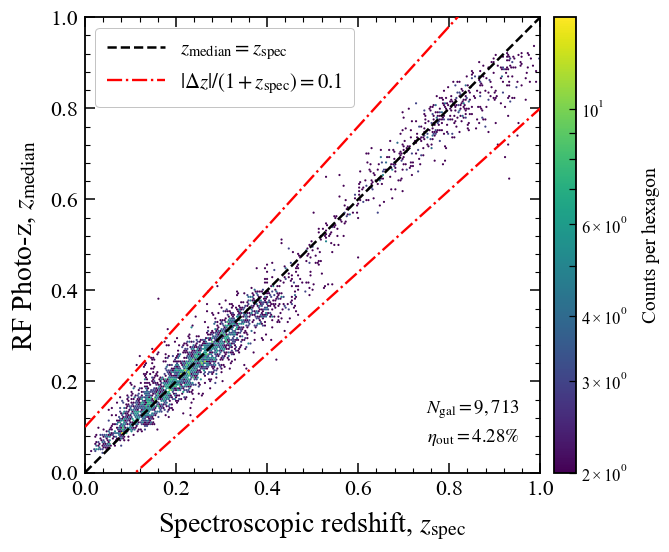

In [75]:
# ============================================================
# Large MNRAS-style figure
# Suitable for a double-column figure
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",

    "font.size": 17,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 15,

    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
})
# ============================================================
# Input data
# ============================================================
z_spec = RF[0]
z_median_RF = RF[1]
outlier_threshold=0.1
if z_spec.size != z_median_RF.size:
    raise ValueError(
        f"Array-length mismatch: "
        f"z_spec={z_spec.size:,}, "
        f"z_median={z_median_RF.size:,}"
    )

# ============================================================
# Analysis sample
# Used to calculate N_gal and the outlier fraction
# ============================================================
zspec_min = 0.006
zspec_max = 1.0

analysis_mask = (
    np.isfinite(z_spec)
    & np.isfinite(z_median_RF)
    & (z_spec >= zspec_min)
    & (z_spec <= zspec_max)
)

z_spec_analysis = z_spec[analysis_mask]
z_median_analysis = z_median_RF[analysis_mask]

# ============================================================
# Catastrophic-outlier definition
# ============================================================
delta_z_normalized = (
    z_median_analysis - z_spec_analysis
) / (1.0 + z_spec_analysis)

# Bias: median normalized residual
bias = np.median(delta_z_normalized)

# Mean bias, optional diagnostic
mean_bias = np.mean(delta_z_normalized)

# Normalized median absolute deviation
sigma_nmad = 1.4826 * np.median(
    np.abs(delta_z_normalized - bias)
)

# Catastrophic outliers
outlier_mask = (
    np.abs(delta_z_normalized) > outlier_threshold
)

n_gal = z_spec_analysis.size
n_outlier = np.count_nonzero(outlier_mask)
outlier_fraction = n_outlier / n_gal

print(f"Number of galaxies:  {n_gal:,}")
print(f"Median bias:         {bias:+.6f}")
print(f"Mean bias:           {mean_bias:+.6f}")
print(f"sigma_NMAD:          {sigma_nmad:.6f}")
print(f"Number of outliers:  {n_outlier:,}")
print(f"Outlier fraction:    {100 * outlier_fraction:.3f}%")
# ============================================================
# Plot range
#
# The plot range does not affect the outlier-fraction calculation.
# ============================================================
x_min, x_max = 0.0, 1.0
y_min, y_max = 0.0, 1.0

plot_mask = (
    (z_spec_analysis >= x_min)
    & (z_spec_analysis <= x_max)
    & (z_median_analysis >= y_min)
    & (z_median_analysis <= y_max)
)

z_spec_plot = z_spec_analysis[plot_mask]
z_median_plot = z_median_analysis[plot_mask]

# ============================================================
# Reference lines
# ============================================================
z_grid = np.linspace(x_min, x_max, 800)

upper_outlier = (
    z_grid
    + outlier_threshold * (1.0 + z_grid)
)

lower_outlier = (
    z_grid
    - outlier_threshold * (1.0 + z_grid)
)

# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(6.8, 5.7))

hb = ax.hexbin(
    z_spec_plot,
    z_median_plot,
    gridsize=220,
    extent=(x_min, x_max, y_min, y_max),
    mincnt=2,
    norm=LogNorm(),
    cmap="viridis",
    linewidths=0,
    rasterized=True,
    zorder=1,
)

# One-to-one relation
ax.plot(
    z_grid,
    z_grid,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=r"$z_{\rm median}=z_{\rm spec}$",
    zorder=5,
)

# Outlier boundaries
ax.plot(
    z_grid,
    upper_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    zorder=4,
)

ax.plot(
    z_grid,
    lower_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    label=rf"$|\Delta z|/(1+z_{{\rm spec}})={outlier_threshold:.1f}$",
    zorder=4,
)

# ============================================================
# Axes formatting
# ============================================================
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$",
    labelpad=8,
)

ax.set_ylabel(
    r"RF Photo-z, $z_{\rm median}$",
    labelpad=9,
)

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    top=True,
    right=True,
    length=7,
    width=1.1,
    pad=5,
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=3.5,
    width=0.8,
)

ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

# ============================================================
# Legend
# ============================================================
legend = ax.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.94,
    facecolor="white",
    edgecolor="0.75",
    borderpad=0.55,
    labelspacing=0.45,
    handlelength=2.8,
    handletextpad=0.7,
)

legend.get_frame().set_linewidth(0.7)
legend.set_zorder(20)

# ============================================================
# Numerical annotation
# ============================================================
annotation = (
    rf"$N_{{\rm gal}}={n_gal:,}$"
    "\n"
    rf"$\eta_{{\rm out}}={100*outlier_fraction:.2f}\%$"
)

ax.text(
    0.955,
    0.055,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=13.5,
    linespacing=1.35,
    color="black",
    zorder=20,
     bbox={
        "boxstyle": "round,pad=0.30",
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.90,
    },
)

# ============================================================
# Colorbar
# ============================================================
cbar = fig.colorbar(
    hb,
    ax=ax,
    pad=0.025,
    fraction=0.050,
)

cbar.set_label(
    "Counts per hexagon",
    fontsize=14,
    labelpad=10,
)

cbar.ax.tick_params(
    which="both",
    direction="in",
    labelsize=12,
    length=5,
    width=0.9,
)

# ============================================================
# Save
# ============================================================
fig.tight_layout(pad=0.8)

fig.savefig(
    "RF_zmedian_zspec_hexbin_large.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "RF_zmedian_zspec_hexbin_large.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()

Number of galaxies:  9,713
Median bias:         -0.002091
Mean bias:           -0.000078
sigma_NMAD:          0.029911
Number of outliers:  336
Outlier fraction:    3.459%


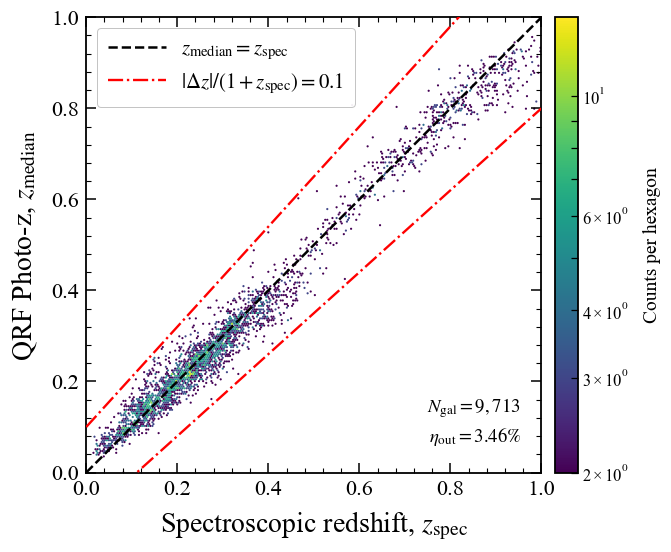

In [76]:
# ============================================================
# Large MNRAS-style figure
# Suitable for a double-column figure
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",

    "font.size": 17,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 15,

    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
})
# ============================================================
# Input data
# ============================================================
z_spec = QRF[0]
z_median_QRF = QRF[1]
outlier_threshold=0.10
if z_spec.size != z_median_QRF.size:
    raise ValueError(
        f"Array-length mismatch: "
        f"z_spec={z_spec.size:,}, "
        f"z_median={z_median_QRF.size:,}"
    )

# ============================================================
# Analysis sample
# Used to calculate N_gal and the outlier fraction
# ============================================================
zspec_min = 0.006
zspec_max = 1.0

analysis_mask = (
    np.isfinite(z_spec)
    & np.isfinite(z_median_QRF)
    & (z_spec >= zspec_min)
    & (z_spec <= zspec_max)
)

z_spec_analysis = z_spec[analysis_mask]
z_median_analysis = z_median_QRF[analysis_mask]

# ============================================================
# Catastrophic-outlier definition
# ============================================================
delta_z_normalized = (
    z_median_analysis - z_spec_analysis
) / (1.0 + z_spec_analysis)

# Bias: median normalized residual
bias = np.median(delta_z_normalized)

# Mean bias, optional diagnostic
mean_bias = np.mean(delta_z_normalized)

# Normalized median absolute deviation
sigma_nmad = 1.4826 * np.median(
    np.abs(delta_z_normalized - bias)
)

# Catastrophic outliers
outlier_mask = (
    np.abs(delta_z_normalized) > outlier_threshold
)

n_gal = z_spec_analysis.size
n_outlier = np.count_nonzero(outlier_mask)
outlier_fraction = n_outlier / n_gal

print(f"Number of galaxies:  {n_gal:,}")
print(f"Median bias:         {bias:+.6f}")
print(f"Mean bias:           {mean_bias:+.6f}")
print(f"sigma_NMAD:          {sigma_nmad:.6f}")
print(f"Number of outliers:  {n_outlier:,}")
print(f"Outlier fraction:    {100 * outlier_fraction:.3f}%")
# ============================================================
# Plot range
#
# The plot range does not affect the outlier-fraction calculation.
# ============================================================
x_min, x_max = 0.0, 1.0
y_min, y_max = 0.0, 1.0

plot_mask = (
    (z_spec_analysis >= x_min)
    & (z_spec_analysis <= x_max)
    & (z_median_analysis >= y_min)
    & (z_median_analysis <= y_max)
)

z_spec_plot = z_spec_analysis[plot_mask]
z_median_plot = z_median_analysis[plot_mask]

# ============================================================
# Reference lines
# ============================================================
z_grid = np.linspace(x_min, x_max, 800)

upper_outlier = (
    z_grid
    + outlier_threshold * (1.0 + z_grid)
)

lower_outlier = (
    z_grid
    - outlier_threshold * (1.0 + z_grid)
)

# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(6.8, 5.7))

hb = ax.hexbin(
    z_spec_plot,
    z_median_plot,
    gridsize=220,
    extent=(x_min, x_max, y_min, y_max),
    mincnt=2,
    norm=LogNorm(),
    cmap="viridis",
    linewidths=0,
    rasterized=True,
    zorder=1,
)

# One-to-one relation
ax.plot(
    z_grid,
    z_grid,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=r"$z_{\rm median}=z_{\rm spec}$",
    zorder=5,
)

# Outlier boundaries
ax.plot(
    z_grid,
    upper_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    zorder=4,
)

ax.plot(
    z_grid,
    lower_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    label=rf"$|\Delta z|/(1+z_{{\rm spec}})={outlier_threshold:.1f}$",
    zorder=4,
)

# ============================================================
# Axes formatting
# ============================================================
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$",
    labelpad=8,
)

ax.set_ylabel(
    r"QRF Photo-z, $z_{\rm median}$",
    labelpad=9,
)

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    top=True,
    right=True,
    length=7,
    width=1.1,
    pad=5,
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=3.5,
    width=0.8,
)

ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

# ============================================================
# Legend
# ============================================================
legend = ax.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.94,
    facecolor="white",
    edgecolor="0.75",
    borderpad=0.55,
    labelspacing=0.45,
    handlelength=2.8,
    handletextpad=0.7,
)

legend.get_frame().set_linewidth(0.7)
legend.set_zorder(20)

# ============================================================
# Numerical annotation
# ============================================================
annotation = (
    rf"$N_{{\rm gal}}={n_gal:,}$"
    "\n"
    rf"$\eta_{{\rm out}}={100*outlier_fraction:.2f}\%$"
)

ax.text(
    0.955,
    0.055,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=13.5,
    linespacing=1.35,
    color="black",
    zorder=20,
     bbox={
        "boxstyle": "round,pad=0.30",
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.90,
    },
)

# ============================================================
# Colorbar
# ============================================================
cbar = fig.colorbar(
    hb,
    ax=ax,
    pad=0.025,
    fraction=0.050,
)

cbar.set_label(
    "Counts per hexagon",
    fontsize=14,
    labelpad=10,
)

cbar.ax.tick_params(
    which="both",
    direction="in",
    labelsize=12,
    length=5,
    width=0.9,
)

# ============================================================
# Save
# ============================================================
fig.tight_layout(pad=0.8)

fig.savefig(
    "QRF_zmedian_zspec_hexbin_large.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "QRF_zmedian_zspec_hexbin_large.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()

Number of galaxies:  9,713
Median bias:         -0.000313
Mean bias:           +0.000023
sigma_NMAD:          0.021278
Number of outliers:  295
Outlier fraction:    3.0372%


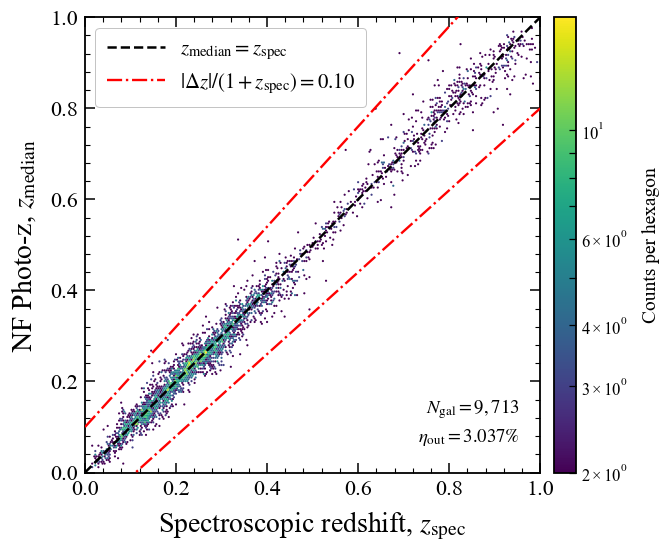

In [77]:
# ============================================================
# Large MNRAS-style figure
# Suitable for a double-column figure
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",

    "font.size": 17,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 15,

    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
})
# ============================================================
# Input data
# ============================================================
z_spec = np.asarray(zs).reshape(-1)
z_median_NF = z_median

if z_spec.size != z_median.size:
    raise ValueError(
        f"Array-length mismatch: "
        f"z_spec={z_spec.size:,}, "
        f"z_median={z_median.size:,}"
    )

# ============================================================
# Analysis sample
# Used to calculate N_gal and the outlier fraction
# ============================================================
zspec_min = 0.006
zspec_max = 1.0

analysis_mask = (
    np.isfinite(z_spec)
    & np.isfinite(z_median)
    & (z_spec >= zspec_min)
    & (z_spec <= zspec_max)
)

z_spec_analysis = z_spec[analysis_mask]
z_median_analysis = z_median_NF[analysis_mask]
outlier_threshold=0.10
# ============================================================
# Catastrophic-outlier definition
# ============================================================
delta_z_normalized = (
    z_median_analysis - z_spec_analysis
) / (1.0 + z_spec_analysis)

# Bias: median normalized residual
bias = np.median(delta_z_normalized)

# Mean bias, optional diagnostic
mean_bias = np.mean(delta_z_normalized)

# Normalized median absolute deviation
sigma_nmad = 1.4826 * np.median(
    np.abs(delta_z_normalized - bias)
)

# Catastrophic outliers
outlier_mask = (
    np.abs(delta_z_normalized) > outlier_threshold
)

n_gal = z_spec_analysis.size
n_outlier = np.count_nonzero(outlier_mask)
outlier_fraction = n_outlier / n_gal

print(f"Number of galaxies:  {n_gal:,}")
print(f"Median bias:         {bias:+.6f}")
print(f"Mean bias:           {mean_bias:+.6f}")
print(f"sigma_NMAD:          {sigma_nmad:.6f}")
print(f"Number of outliers:  {n_outlier:,}")
print(f"Outlier fraction:    {100 * outlier_fraction:.4f}%")

# ============================================================
# Plot range
#
# The plot range does not affect the outlier-fraction calculation.
# ============================================================
x_min, x_max = 0.0, 1.0
y_min, y_max = 0.0, 1.0

plot_mask = (
    (z_spec_analysis >= x_min)
    & (z_spec_analysis <= x_max)
    & (z_median_analysis >= y_min)
    & (z_median_analysis <= y_max)
)

z_spec_plot = z_spec_analysis[plot_mask]
z_median_plot = z_median_analysis[plot_mask]

# ============================================================
# Reference lines
# ============================================================
z_grid = np.linspace(x_min, x_max, 800)

upper_outlier = (
    z_grid
    + outlier_threshold * (1.0 + z_grid)
)

lower_outlier = (
    z_grid
    - outlier_threshold * (1.0 + z_grid)
)

# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(6.8, 5.7))

hb = ax.hexbin(
    z_spec_plot,
    z_median_plot,
    gridsize=220,
    extent=(x_min, x_max, y_min, y_max),
    mincnt=2,
    norm=LogNorm(),
    cmap="viridis",
    linewidths=0,
    rasterized=True,
    zorder=1,
)

# One-to-one relation
ax.plot(
    z_grid,
    z_grid,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=r"$z_{\rm median}=z_{\rm spec}$",
    zorder=5,
)

# Outlier boundaries
ax.plot(
    z_grid,
    upper_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    zorder=4,
)

ax.plot(
    z_grid,
    lower_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    label=rf"$|\Delta z|/(1+z_{{\rm spec}})={outlier_threshold:.2f}$",
    zorder=4,
)

# ============================================================
# Axes formatting
# ============================================================
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$",
    labelpad=8,
)

ax.set_ylabel(
    r"NF Photo-z, $z_{\rm median}$",
    labelpad=9,
)

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    top=True,
    right=True,
    length=7,
    width=1.1,
    pad=5,
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=3.5,
    width=0.8,
)

ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

# ============================================================
# Legend
# ============================================================
legend = ax.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.94,
    facecolor="white",
    edgecolor="0.75",
    borderpad=0.55,
    labelspacing=0.45,
    handlelength=2.8,
    handletextpad=0.7,
)

legend.get_frame().set_linewidth(0.7)
legend.set_zorder(20)

# ============================================================
# Numerical annotation
# ============================================================
annotation = (
    rf"$N_{{\rm gal}}={n_gal:,}$"
    "\n"
    rf"$\eta_{{\rm out}}={100*outlier_fraction:.3f}\%$"
)

ax.text(
    0.955,
    0.055,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=13.5,
    linespacing=1.35,
    color="black",
    zorder=20,
     bbox={
        "boxstyle": "round,pad=0.30",
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.90,
    },
)

# ============================================================
# Colorbar
# ============================================================
cbar = fig.colorbar(
    hb,
    ax=ax,
    pad=0.025,
    fraction=0.050,
)

cbar.set_label(
    "Counts per hexagon",
    fontsize=14,
    labelpad=10,
)

cbar.ax.tick_params(
    which="both",
    direction="in",
    labelsize=12,
    length=5,
    width=0.9,
)

# ============================================================
# Save
# ============================================================
fig.tight_layout(pad=0.8)

fig.savefig(
    "NF_zmedian_zspec_hexbin_large.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "NF_zmedian_zspec_hexbin_large.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()

## 8. Feature saliency
Input-gradient saliency is evaluated using the **loaded/trained** flow transforms. The older duplicate saliency implementation and the cell that recreated a fresh, untrained transform have been removed.


In [78]:
# Use the trained transform returned by load_model; do not recreate a fresh flow here.
train_loader = DataLoader(
    TensorDataset(x1_train, x2_train),
    batch_size=batch_size,
    shuffle=True,
)


In [79]:
def flow_parameter_significance(
    x2_transform,
    dist_x2_given_x1,
    loader,
    device=None,
    max_batches=None,
):
    """
    Estimate feature significance for a conditional flow p(x2 | x1)
    using input-gradient saliency.

    Returns
    -------
    median_sal : ndarray
        Median absolute saliency for each feature.

    rel_imp : ndarray
        Median saliency normalized by the largest median saliency.

    spread : ndarray, shape (2, n_features)
        Asymmetric 16th--84th percentile range, normalized by the
        same maximum median saliency.
        spread[0] = lower error
        spread[1] = upper error
    """

    if device is None:
        device = next(x2_transform.parameters()).device

    x2_transform.eval()

    all_saliency = []

    for b, batch in enumerate(loader):

        if max_batches is not None and b >= max_batches:
            break

        if isinstance(batch, (list, tuple)) and len(batch) >= 2:
            x1_batch, x2_batch = batch[0], batch[1]
        else:
            raise RuntimeError(
                "Adjust batch unpacking to match DataLoader output."
            )

        # Use the actual batch
        x1_batch = (
            x1_batch
            .to(device)
            .detach()
            .requires_grad_(True)
        )

        x2_batch = x2_batch.to(device)

        # Conditional distribution
        cond_dist = dist_x2_given_x1.condition(x1_batch)

        logp = cond_dist.log_prob(x2_batch)

        # Sum gives per-object gradients without 1/B scaling
        loss = -logp.sum()

        grad = torch.autograd.grad(
            loss,
            x1_batch,
            retain_graph=False,
            create_graph=False,
        )[0]

        batch_saliency = grad.detach().abs().cpu()

        all_saliency.append(batch_saliency)

    # (N_objects, N_features)
    saliency = torch.cat(all_saliency, dim=0)

    print("Saliency shape:", saliency.shape)

    # Robust statistics
    median_sal = torch.median(saliency, dim=0).values
    q16 = torch.quantile(saliency, 0.16, dim=0)
    q84 = torch.quantile(saliency, 0.84, dim=0)

    median_sal_np = median_sal.numpy()
    q16_np = q16.numpy()
    q84_np = q84.numpy()

    # Normalize using maximum MEDIAN saliency
    norm = median_sal_np.max()

    rel_imp = median_sal_np / norm

    # asymmetric percentile ranges
    lower = (median_sal_np - q16_np) / norm
    upper = (q84_np - median_sal_np) / norm

    spread = np.vstack([lower, upper])

    return median_sal_np, rel_imp, spread

In [80]:
device = next(x2_transform.parameters()).device
median_sal, rel_imp, spread = flow_parameter_significance(
    x2_transform,
    dist_x2_given_x1,
    train_loader,       # your training DataLoader
    device=device,
    max_batches=200,    # optional, for speed
)


Saliency shape: torch.Size([12784, 23])


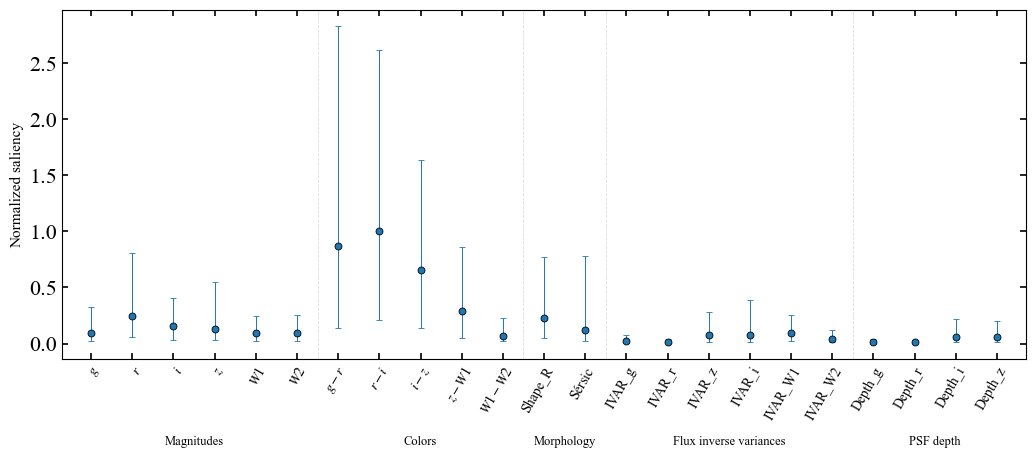

In [81]:
idx = np.arange(len(median_sal))

param_names = [
    r"$g$", r"$r$", r"$i$", r"$z$", r"$W1$", r"$W2$",
    r"$g-r$", r"$r-i$", r"$i-z$", r"$z-W1$", r"$W1-W2$",
    "Shape_R", r"${\rm Sérsic}$",
    "IVAR_g", "IVAR_r",
    "IVAR_z", "IVAR_i",
    "IVAR_W1", "IVAR_W2",
    "Depth_g", "Depth_r",
    "Depth_i", "Depth_z"
]

fig, ax = plt.subplots(figsize=(10.5, 4.8))

ax.errorbar(
    idx,
    rel_imp,
    yerr=spread,
    fmt="o",
    markersize=5,
    markeredgecolor="black",
    markeredgewidth=0.6,
    elinewidth=0.7,
    capsize=2,
    capthick=0.7
)
ax.set_xticks(idx)
ax.set_xticklabels(
    param_names,
    rotation=60,
    ha="right",
    rotation_mode="anchor",
    fontsize=10
)

ax.set_ylabel("Normalized saliency", fontsize=11)

ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.set_xlim(-0.7, len(idx) - 0.3)
groups = [
    (0, 5, "Magnitudes"),
    (6, 10, "Colors"),
    (11, 12, "Morphology"),
    (13, 18, "Flux inverse variances"),
    (19, 22, "PSF depth"),
]
for start, end, label in groups:
    centre = (start + end) / 2
    ax.text(
        centre,
        -0.22,   # 原来如果是 -0.28，可以改近一些
        label,
        ha="center",
        va="top",
        transform=ax.get_xaxis_transform(),
        fontsize=9
    )
for x in [5.5, 10.5, 12.5, 18.5]:
    ax.axvline(
        x,
        color="0.8",
        linestyle="--",
        linewidth=0.6,
        alpha=0.7,
    )

for spine in ax.spines.values():
    spine.set_linewidth(0.8)
plt.subplots_adjust(bottom=0.24)

plt.tight_layout()
plt.savefig(
    "feature_saliency.pdf",
    bbox_inches="tight"
)
plt.show()


## ECDF Calibration

Derive the ECDF-based calibration mapping from the NF predictions on the validation sample, save the mapping, and apply it to the independent testing sample. Then evaluate the improvement in the PIT distribution and generate the recalibrated PDFs for the testing sample.


In [84]:
#output validation samples NF PDFs prediction
zs_val = scaler_x.inverse_transform(x2_validate.detach().cpu().numpy().reshape(-1, 1)).flatten()
x2_flow_val,z_maxp_val, z_median_val, z_mean_val, err_std_val, err_68halfpc_val= test_sample_dist( x1_validate, x2_validate, zs_val, mean, std )

In [85]:
from tqdm.auto import tqdm
def evaluate_base_cdf(base_dist, latent):
    """
    Evaluate a one-dimensional base-distribution CDF.
    """

    if isinstance(base_dist, torch.distributions.Independent):
        return base_dist.base_dist.cdf(latent)

    return base_dist.cdf(latent)


@torch.no_grad()
def calculate_exact_pit_manual(
    dist_x2_given_x1,
    x2_transform,
    x1_test,
    x2_test,
    chunk_size=20_000,
):
    x2_transform.eval()

    parameter = next(x2_transform.parameters())
    device = parameter.device
    dtype = parameter.dtype

    x1_test = torch.as_tensor(
        x1_test,
        dtype=dtype,
        device=device,
    )

    x2_test = torch.as_tensor(
        x2_test,
        dtype=dtype,
        device=device,
    ).reshape(-1, 1)

    pit_chunks = []

    for start in tqdm(
        range(0, len(x2_test), chunk_size),
        desc="Exact PIT",
    ):
        stop = min(start + chunk_size, len(x2_test))

        context_chunk = x1_test[start:stop]
        redshift_chunk = x2_test[start:stop]

        conditioned_dist = dist_x2_given_x1.condition(
            context_chunk
        )

        latent = redshift_chunk

        # Correct: reverse the transform list.
        for transform in conditioned_dist.transforms[::-1]:
            latent = transform.inv(latent)

        pit_chunk = evaluate_base_cdf(
            conditioned_dist.base_dist,
            latent,
        )

        pit_chunks.append(
            pit_chunk.reshape(-1).cpu()
        )

    pit = torch.cat(pit_chunks).numpy()

    return np.clip(pit, 0.0, 1.0)

In [86]:
def fit_pit_mapping(pit, n_knots=101):
    """
    Fit empirical PIT recalibration mapping.

    Returns
    -------
    q_knots : calibrated quantile levels
    u_knots : corresponding raw PIT values
    """

    pit = np.asarray(pit)
    pit = pit[np.isfinite(pit)]
    pit = np.clip(pit, 0.0, 1.0)

    q_knots = np.linspace(0.0, 1.0, n_knots)

    # G^{-1}(q)
    u_knots = np.quantile(
        pit,
        q_knots
    )

    # force exact boundaries
    u_knots[0] = 0.0
    u_knots[-1] = 1.0

    return q_knots, u_knots

In [87]:
#calculate the origional PIT for testing samples
pit_exact=calculate_exact_pit_manual(
    dist_x2_given_x1,
    x2_transform,
    x1_test[zs>0.006],
    x2_test[zs>0.006],
    chunk_size=50_000,
)

Exact PIT:   0%|          | 0/1 [00:00<?, ?it/s]

In [88]:
#calculate the validation samples PIT
pit_val=calculate_exact_pit_manual(
    dist_x2_given_x1,
    x2_transform,
    x1_validate[zs_val>0.006],
    x2_validate[zs_val>0.006],
    chunk_size=50_000,
)

Exact PIT:   0%|          | 0/1 [00:00<?, ?it/s]

In [89]:
#define tomographic bins and mask
z_bins=[[0.006,0.2],[0.2,0.4],[0.4,0.6],[0.6,1.0]]
z_median_val_1=z_median_val[zs_val>0.006]
z_median_1=z_median[zs>0.006]

0.006 <= z < 0.200: N=2,501, mean PIT=0.5353, median PIT=0.5494
0.200 <= z < 0.400: N=3,701, mean PIT=0.5082, median PIT=0.5023
0.400 <= z < 0.600: N=1,101, mean PIT=0.5040, median PIT=0.5008
0.600 <= z < 1.000: N=2,379, mean PIT=0.4773, median PIT=0.4564


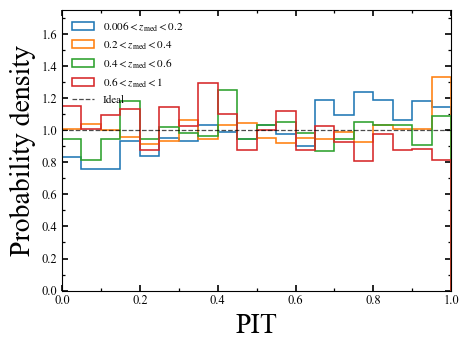

In [90]:
#4 tomographic bins PIT
z_bins = [
    (0.006, 0.2),
    (0.2, 0.4),
    (0.4, 0.6),
    (0.6, 1.0),
]

pit_bins = np.linspace(0.0, 1.0, 21)

fig, ax = plt.subplots(figsize=(5.0, 3.8))

for z_min, z_max in z_bins:

    mask = (
        np.isfinite(z_median_1)
        & np.isfinite(pit_exact)
        & (z_median_1 >= z_min)
        & (z_median_1 < z_max)
    )

    pit_bin = pit_exact[mask]

    print(
        f"{z_min:.3f} <= z < {z_max:.3f}: "
        f"N={len(pit_bin):,}, "
        f"mean PIT={np.mean(pit_bin):.4f}, "
        f"median PIT={np.median(pit_bin):.4f}"
    )

    ax.hist(
        pit_bin,
        bins=pit_bins,
        density=True,
        histtype="step",
        linewidth=1.15,
        label=rf"${z_min:g}<z_{{\rm med}}<{z_max:g}$",
    )

# Ideal uniform PIT
ax.axhline(
    1.0,
    color="k",
    linestyle="--",
    linewidth=0.9,
    alpha=0.7,
    label="Ideal",
)

ax.set_xlabel("PIT")
ax.set_ylabel("Probability density")

ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.75)

# MNRAS-like ticks
ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
    labelsize=9,
)

ax.tick_params(which="major", length=4)
ax.tick_params(which="minor", length=2)

ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.yaxis.set_minor_locator(AutoMinorLocator(2))

# Thin spines
for spine in ax.spines.values():
    spine.set_linewidth(0.8)

ax.legend(
    fontsize=8,
    frameon=False,
    loc="upper left",
)

fig.tight_layout()
plt.show()

In [91]:
#calibration on 4 tomographic bins respectively
calibrators = {}

for i, (zmin, zmax) in enumerate(z_bins):

    mask = (
        (z_median_val_1>= zmin)
        & (z_median_val_1 < zmax)
    )

    q_knots, u_knots = fit_pit_mapping(
        pit_val[mask],
        n_knots=101,
    )

    calibrators[i] = {
        "q": q_knots,
        "u": u_knots,
    }

In [92]:
def calibrate_pit(pit, q_knots, u_knots):

    # remove repeated u values for interpolation
    u_unique, index = np.unique(
        u_knots,
        return_index=True
    )

    q_unique = q_knots[index]

    return np.interp(
        pit,
        u_unique,
        q_unique,
        left=0.0,
        right=1.0,
    )

In [93]:
#output validation samples calibrated PIT
pit_val_cal = np.zeros_like(pit_val)

for i, (zmin, zmax) in enumerate(z_bins):

    mask = (
        (z_median_val_1 >= zmin)
        & (z_median_val_1 < zmax)
    )

    pit_val_cal[mask] = calibrate_pit(
        pit_val[mask],
        calibrators[i]["q"],
        calibrators[i]["u"],
    )

In [94]:
#output testing samples calibrated PIT
pit_test_cal = np.zeros_like(pit_exact)

for i, (zmin, zmax) in enumerate(z_bins):

    mask = (
        (z_median_1 >= zmin)
        & (z_median_1 < zmax)
    )

    pit_test_cal[mask] = calibrate_pit(
        pit_exact[mask],
        calibrators[i]["q"],
        calibrators[i]["u"],
    )

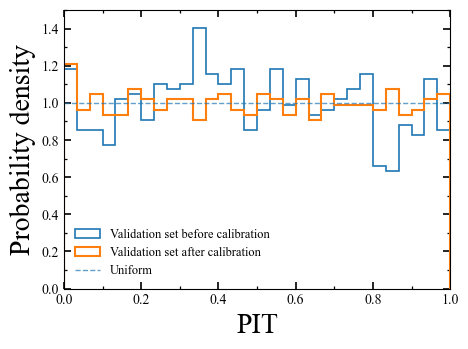

In [95]:
fig, ax = plt.subplots(figsize=(5.0, 3.8))

bins = np.linspace(0.0, 1.0, 31)

# Before calibration
ax.hist(
    pit_val,
    bins=bins,
    density=True,
    histtype='step',
    linewidth=1.2,
    label='Validation set before calibration'
)

# After calibration
ax.hist(
    pit_val_cal,
    bins=bins,
    density=True,
    histtype='step',
    linewidth=1.5,
    label='Validation set after calibration'
)

# Ideal PIT distribution
ax.axhline(
    1.0,
    linestyle='--',
    linewidth=1.0,
    alpha=0.7,
    label='Uniform'
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.5)

ax.set_xlabel('PIT')
ax.set_ylabel('Probability density')

# MNRAS-like ticks
ax.tick_params(
    axis='both',
    which='both',
    direction='in',
    top=True,
    right=True,
    labelsize=10
)

ax.tick_params(which='major', length=5)
ax.tick_params(which='minor', length=2.5)

ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.yaxis.set_minor_locator(AutoMinorLocator(2))

# Legend
ax.legend(
    frameon=False,
    fontsize=9,
    loc='best'
)

# Slightly thinner spines
for spine in ax.spines.values():
    spine.set_linewidth(0.8)

fig.tight_layout()
plt.show()

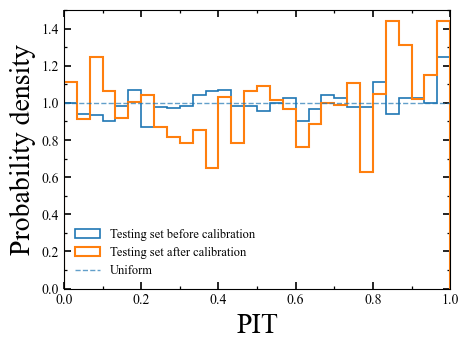

In [96]:
fig, ax = plt.subplots(figsize=(5.0, 3.8))

bins = np.linspace(0.0, 1.0, 31)

# Before calibration
ax.hist(
    pit_exact,
    bins=bins,
    density=True,
    histtype='step',
    linewidth=1.2,
    label='Testing set before calibration'
)

# After calibration
ax.hist(
    pit_test_cal,
    bins=bins,
    density=True,
    histtype='step',
    linewidth=1.5,
    label='Testing set after calibration'
)

# Ideal PIT distribution
ax.axhline(
    1.0,
    linestyle='--',
    linewidth=1.0,
    alpha=0.7,
    label='Uniform'
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.5)

ax.set_xlabel('PIT')
ax.set_ylabel('Probability density')

# MNRAS-like ticks
ax.tick_params(
    axis='both',
    which='both',
    direction='in',
    top=True,
    right=True,
    labelsize=10
)

ax.tick_params(which='major', length=5)
ax.tick_params(which='minor', length=2.5)

ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.yaxis.set_minor_locator(AutoMinorLocator(2))

# Legend
ax.legend(
    frameon=False,
    fontsize=9,
    loc='best'
)

# Slightly thinner spines
for spine in ax.spines.values():
    spine.set_linewidth(0.8)

fig.tight_layout()
plt.show()

D_PIT before = 0.01435
D_PIT after  = 0.04771


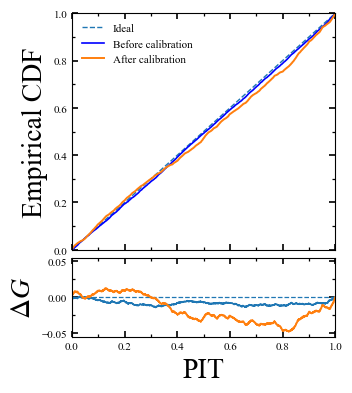

In [97]:
def empirical_cdf(pit):
    pit = np.asarray(pit)
    pit = pit[np.isfinite(pit)]
    pit = np.sort(pit)

    n = len(pit)
    ecdf = np.arange(1, n + 1) / n

    return pit, ecdf


# -------------------------------------------------
# Compute empirical CDFs
# -------------------------------------------------

x_before, y_before = empirical_cdf(pit_exact)
x_after,  y_after  = empirical_cdf(pit_test_cal)

# Residual relative to ideal G(u) = u
res_before = y_before - x_before
res_after  = y_after  - x_after

# KS-like maximum deviations
D_before = np.max(np.abs(res_before))
D_after  = np.max(np.abs(res_after))

print(f"D_PIT before = {D_before:.5f}")
print(f"D_PIT after  = {D_after:.5f}")


# -------------------------------------------------
# Downsample only for plotting
# -------------------------------------------------

nplot = 3000

step_before = max(1, len(x_before) // nplot)
step_after  = max(1, len(x_after) // nplot)

xb = x_before[::step_before]
yb = y_before[::step_before]
rb = res_before[::step_before]

xa = x_after[::step_after]
ya = y_after[::step_after]
ra = res_after[::step_after]


# -------------------------------------------------
# MNRAS-style figure
# -------------------------------------------------

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(3.4, 4.2),
    sharex=True,
    gridspec_kw={
        'height_ratios': [3.0, 1.0],
        'hspace': 0.05
    }
)


# =========================
# Upper panel: empirical CDF
# =========================

ax.plot(
    [0, 1], [0, 1],
    ls='--',
    lw=1.0,
    label='Ideal'
)

ax.plot(
    xb, yb,
    lw=1.2,
    label='Before calibration',
    c='blue'
)

ax.plot(
    xa, ya,
    lw=1.4,
    label='After calibration'
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_ylabel('Empirical CDF')

ax.legend(
    frameon=False,
    fontsize=8,
    loc='upper left'
)


# =========================
# Lower panel: residual
# =========================

axr.axhline(
    0,
    ls='--',
    lw=0.9
)

axr.plot(
    xb, rb,
    lw=1.2,
    label='Before calibration'
)

axr.plot(
    xa, ra,
    lw=1.4,
    label='After calibration'
)

axr.set_xlim(0, 1)

axr.set_xlabel('PIT')
axr.set_ylabel(r'$\Delta G$')


# Symmetric residual range
max_res = max(
    np.max(np.abs(res_before)),
    np.max(np.abs(res_after))
)

axr.set_ylim(
    -1.15 * max_res,
     1.15 * max_res
)


# -------------------------------------------------
# MNRAS-like ticks
# -------------------------------------------------

for a in (ax, axr):

    a.tick_params(
        axis='both',
        which='both',
        direction='in',
        top=True,
        right=True,
        labelsize=8
    )

    a.tick_params(
        which='major',
        length=4
    )

    a.tick_params(
        which='minor',
        length=2
    )

    a.xaxis.set_minor_locator(
        AutoMinorLocator(2)
    )

    a.yaxis.set_minor_locator(
        AutoMinorLocator(2)
    )

    for spine in a.spines.values():
        spine.set_linewidth(0.8)


plt.show()

In [98]:
def recalibrate_pdfs_four_bins(
    NF_samples,
    zmedian,
    calibrators,
    z_bins=z_bins,
    n_samples=200,
    chunk_size=100_000,
):
    """
    Apply redshift-dependent PIT/CDF recalibration to NF PDFs.

    Parameters
    ----------
    NF_samples : ndarray
        Raw NF Monte Carlo PDF samples.
        Shape = (N_gal, n_samples)

    zmedian : ndarray
        Raw NF posterior median used to assign galaxies
        to calibration bins.
        Shape = (N_gal,)

    calibrators : dict
        calibrators[i]["q"] = calibrated quantile grid
        calibrators[i]["u"] = corresponding raw quantiles,
        i.e. G_i^{-1}(q)

    z_bins : list
        Redshift bins for calibration.

    n_samples : int
        Number of samples used to represent each calibrated PDF.

    chunk_size : int
        Number of galaxies processed at once.

    Returns
    -------
    calibrated_samples : ndarray
        Calibrated PDF samples.
        Shape = (N_gal, n_samples)
    """

    NF_samples = np.asarray(NF_samples)
    zmedian = np.asarray(zmedian)

    n_gal = len(zmedian)

    calibrated_samples = np.empty(
        (n_gal, n_samples),
        dtype=np.float32,
    )

    # By default keep the original PDFs.
    # This is useful for galaxies outside the four calibration bins.
    calibrated_samples[:] = NF_samples.astype(
        np.float32,
        copy=False,
    )

    # Uniform quantiles of the calibrated PDF
    q_cal = (
        np.arange(n_samples, dtype=np.float64) + 0.5
    ) / n_samples

    for ibin, (zmin, zmax) in enumerate(z_bins):

        print(
            f"Calibrating bin {ibin + 1}: "
            f"{zmin} <= z_median < {zmax}"
        )

        mask = (
            (zmedian >= zmin)
            & (zmedian < zmax)
        )

        indices = np.where(mask)[0]

        print(
            f"N_gal = {len(indices):,}"
        )

        if len(indices) == 0:
            continue

        q_knots = np.asarray(
            calibrators[ibin]["q"],
            dtype=np.float64,
        )

        u_knots = np.asarray(
            calibrators[ibin]["u"],
            dtype=np.float64,
        )

        # ----------------------------------------------------
        # G^{-1}(q)
        # calibrated quantile -> raw PDF quantile
        # ----------------------------------------------------

        q_raw = np.interp(
            q_cal,
            q_knots,
            u_knots,
        )

        q_raw = np.clip(
            q_raw,
            0.0,
            1.0,
        )

        # ----------------------------------------------------
        # Process galaxies in chunks
        # ----------------------------------------------------

        for start in range(
            0,
            len(indices),
            chunk_size,
        ):

            stop = min(
                start + chunk_size,
                len(indices),
            )

            idx = indices[start:stop]

            raw_chunk = np.asarray(
                NF_samples[idx],
                dtype=np.float32,
            )

            # F_cal^{-1}(q)
            # = F_raw^{-1}[G^{-1}(q)]
            cal_chunk = np.quantile(
                raw_chunk,
                q_raw,
                axis=1,
            ).T

            calibrated_samples[idx] = cal_chunk.astype(
                np.float32,
                copy=False,
            )

    return calibrated_samples

In [99]:
#obtain the calibrated NF PDFs, which can be used to make point estimation and N(z) reconstruction
x2_flow_cal = recalibrate_pdfs_four_bins(
    NF_samples=x2_flow[zs>0.006],
    zmedian=z_median_1,
    calibrators=calibrators,
    n_samples=200,
    chunk_size=100_000,
)

Calibrating bin 1: 0.006 <= z_median < 0.2
N_gal = 2,501
Calibrating bin 2: 0.2 <= z_median < 0.4
N_gal = 3,701
Calibrating bin 3: 0.4 <= z_median < 0.6
N_gal = 1,101
Calibrating bin 4: 0.6 <= z_median < 1.0
N_gal = 2,379


In [100]:
#median value of calibrated PDFs
z_median_cal=np.median(x2_flow_cal,axis=1)

## 11. Full-sample $N(z)$ reconstruction
Convert sampled NF PDFs to histograms, apply PDF-quality masking, and compare reconstructed distributions using mean/width shifts, Wasserstein distance, Jensen--Shannon divergence, overlap, RMSE, and $\chi^2$.


In [101]:
def pdf_to_quantiles(pdfs, z_edges, qs=(0.1, 0.2, 0.5, 0.68, 0.95), eps=1e-12):
    """
    pdfs: (Ngal, Nbin)  or (Nbin,)
    z_edges: (Nbin+1,)
    returns: zq (Ngal, len(qs)) or (len(qs),)
    """
    pdfs = np.asarray(pdfs, dtype=float)
    single = (pdfs.ndim == 1)
    if single:
        pdfs = pdfs[None, :]

    z_edges = np.asarray(z_edges, dtype=float)
    dz = np.diff(z_edges)
    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

    # prob mass per bin
    mass = np.clip(pdfs, 0, None) * dz[None, :]
    norm = mass.sum(axis=1, keepdims=True)

    # avoid divide-by-zero
    good_norm = (norm[:, 0] > eps)
    mass[good_norm] /= norm[good_norm]
    mass[~good_norm] = 0.0

    cdf = np.cumsum(mass, axis=1)
    cdf = np.clip(cdf, 0.0, 1.0)

    qs = np.asarray(qs, dtype=float)
    zq = np.empty((pdfs.shape[0], len(qs)), dtype=float)

    for i in range(pdfs.shape[0]):
        if not good_norm[i]:
            zq[i, :] = np.nan
            continue
        zq[i, :] = np.interp(qs, cdf[i], z_centers, left=z_centers[0], right=z_centers[-1])

    return zq[0] if single else zq


# ----------------------------
# 2) bad-PDF detection from quantiles
# ----------------------------
def detect_bad_pdfs_from_quantiles(
    zq,
    z_edges,
    z95_cut=0.01,      # 95% probability still below this => "stuck at zero"
    z50_cut=0.005,      # median extremely small
    width_bins=3,      # collapse threshold = width_bins * dz
    monotonic_tol=1e-6
):
    """
    zq: (Ngal, 5) for qs=[0.1,0.2,0.5,0.68,0.95]
    returns: good_mask, bad_mask, reason (object array of strings)
    """
    zq = np.asarray(zq, dtype=float)
    dz = float(z_edges[1] - z_edges[0]) if np.allclose(np.diff(z_edges), np.diff(z_edges)[0]) else np.median(np.diff(z_edges))
    width_min = width_bins * dz

    # handle NaNs
    nan_bad = np.any(~np.isfinite(zq), axis=1)

    # monotonicity
    nonmono = np.any(np.diff(zq, axis=1) < -monotonic_tol, axis=1)

    z10, z20, z50, z68, z95 = zq.T
    near0_all = (z95 < z95_cut)
    near0_med = (z50 < z50_cut)
    collapse = ((z95 - z10) < width_min)

    bad = nan_bad | nonmono | near0_all | (near0_med & collapse)
    good = ~bad

    reasons = np.empty(zq.shape[0], dtype=object)
    for i in range(zq.shape[0]):
        if good[i]:
            reasons[i] = ""
            continue
        r = []
        if nan_bad[i]: r.append("nan_quantiles")
        if nonmono[i]: r.append("non_monotonic")
        if near0_all[i]: r.append(f"z95<{z95_cut:g}")
        if near0_med[i] and collapse[i]: r.append(f"z50<{z50_cut:g}&(z95-z10)<{width_min:g}")
        reasons[i] = "|".join(r)

    return good, bad, reasons


# ----------------------------
# 3) N(z) stacking (counts per bin) from PDFs
# ----------------------------
def stack_Nz_from_pdfs(pdfs, z_edges, mask=None, weights=None, eps=1e-12):
    """
    pdfs: (Ngal, Nbin) density in linear z (NOT logz)
    returns: Nz (Nbin,), z_centers
    """
    pdfs = np.asarray(pdfs, dtype=float)
    z_edges = np.asarray(z_edges, dtype=float)
    dz = np.diff(z_edges)
    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

    Ngal = pdfs.shape[0]
    if mask is None:
        mask = np.ones(Ngal, dtype=bool)
    else:
        mask = np.asarray(mask, dtype=bool)

    if weights is None:
        weights = np.ones(Ngal, dtype=float)
    else:
        weights = np.asarray(weights, dtype=float)

    pdfs_m = np.clip(pdfs[mask], 0, None)
    w = weights[mask]

    # normalize each PDF (robust to tiny numerical drift)
    mass = pdfs_m * dz[None, :]
    norm = mass.sum(axis=1)
    ok = norm > eps
    pdfs_m = pdfs_m[ok]
    w = w[ok]
    mass = mass[ok] / norm[ok, None]

    # expected counts per bin: sum_j w_j * P(bin)
    Nz = (w[:, None] * mass).sum(axis=0)
    return Nz, z_centers


# ----------------------------
# 4) End-to-end pipeline
# ----------------------------
def pipeline_pdf_to_quantiles_mask_stack(
    pdfs, z_edges,
    qs=(0.1,0.2,0.5,0.68,0.95),
    z95_cut=0.05, z50_cut=0.02, width_bins=3,
    weights=None
):
    # PDF -> quantiles
    zq = pdf_to_quantiles(pdfs, z_edges, qs=qs)

    # bad-PDF detection
    good, bad, reasons = detect_bad_pdfs_from_quantiles(
        zq, z_edges, z95_cut=z95_cut, z50_cut=z50_cut, width_bins=width_bins
    )

    # stacking
    Nz_all, zc = stack_Nz_from_pdfs(pdfs, z_edges, mask=None, weights=weights)
    Nz_good, _ = stack_Nz_from_pdfs(pdfs, z_edges, mask=good, weights=weights)

    out = {
        "zq": zq,
        "good_mask": good,
        "bad_mask": bad,
        "bad_reasons": reasons,
        "Nz_all": Nz_all,
        "Nz_good": Nz_good,
        "z_centers": zc,
        "bad_fraction": bad.mean(),
        "kept_fraction": good.mean()
    }
    return out

In [102]:
#define the bins and select PDFs(zs>0.006)
z_edges = np.linspace(0.006, 1.2, 200)
z_centres = 0.5 * (z_edges[:-1] + z_edges[1:])
x2_flow_modify=x2_flow[zs>0.006]


In [103]:
# stack over all PDFs along the bins
hist=[]
for i in range(len(zs[zs>0.006])): 
    hist.append(np.histogram( x2_flow[i,:], bins=z_edges)[0])

In [104]:
#ouput the normalizing flow N(z), the redshift cut can be freely adjusted
out = pipeline_pdf_to_quantiles_mask_stack(hist, z_edges, z95_cut=0.00001, z50_cut=0.005, width_bins=3)

In [105]:
#define the N(z) comparison metrics
def normalize_distribution(n, z=None):
    """
    Normalize N(z) into a probability distribution.
    If z is given, uses bin width integration.
    """
    n = np.asarray(n, dtype=float)
    if np.any(n < 0):
        raise ValueError("Distribution contains negative values.")
    
    if z is None:
        total = np.sum(n)
    else:
        z = np.asarray(z, dtype=float)
        if len(z) < 2:
            total = np.sum(n)
        else:
            dz = np.gradient(z)
            total = np.sum(n * dz)
    
    if total <= 0:
        raise ValueError("Distribution sum is non-positive.")
    
    return n / total

def weighted_mean_and_sigma(z, n):
    """
    Compute mean redshift and width sigma of N(z).
    n does not need to be normalized.
    """
    z = np.asarray(z, dtype=float)
    n = np.asarray(n, dtype=float)

    w = normalize_distribution(n, z)
    dz = np.gradient(z)

    mean = np.sum(z * w * dz)
    var = np.sum((z - mean)**2 * w * dz)
    sigma = np.sqrt(var)
    return mean, sigma

def rmse(n_pred, n_spec):
    """
    Root mean squared error between two arrays.
    """
    n_pred = np.asarray(n_pred, dtype=float)
    n_spec = np.asarray(n_spec, dtype=float)
    return np.sqrt(np.mean((n_pred - n_spec)**2))

def chi2_poisson(n_pred, n_spec, eps=1e-12):
    """
    Chi-square using Poisson variance from spec counts.
    Suitable when n_spec are counts (not normalized densities).
    """
    n_pred = np.asarray(n_pred, dtype=float)
    n_spec = np.asarray(n_spec, dtype=float)
    var = np.maximum(n_spec, eps)
    return np.sum((n_pred - n_spec)**2 / var)

def overlap_coefficient(n_pred, n_spec, z=None):
    """
    Histogram overlap / intersection.
    Returns value in [0,1].
    """
    p = normalize_distribution(n_pred, z)
    q = normalize_distribution(n_spec, z)

    if z is None:
        return np.sum(np.minimum(p, q))
    else:
        dz = np.gradient(z)
        return np.sum(np.minimum(p, q) * dz)

def residual_metrics(z, n_pred, n_spec, eps=1e-12):
    """
    Return bin-by-bin residuals:
      absolute residual
      fractional residual
    """
    z = np.asarray(z, dtype=float)
    n_pred = np.asarray(n_pred, dtype=float)
    n_spec = np.asarray(n_spec, dtype=float)

    abs_res = n_pred - n_spec
    frac_res = (n_pred - n_spec) / np.maximum(n_spec, eps)

    return {
        "z": z,
        "abs_residual": abs_res,
        "frac_residual": frac_res,
    }

def compare_nz(z, n_pred, n_spec, use_counts_for_chi2=True):
    """
    Compute a suite of comparison metrics for N(z).
    """
    z = np.asarray(z, dtype=float)
    n_pred = np.asarray(n_pred, dtype=float)
    n_spec = np.asarray(n_spec, dtype=float)

    # Moments
    mean_pred, sigma_pred = weighted_mean_and_sigma(z, n_pred)
    mean_spec, sigma_spec = weighted_mean_and_sigma(z, n_spec)

    delta_mean = mean_pred - mean_spec
    delta_sigma = sigma_pred - sigma_spec
    rel_delta_mean = delta_mean / (1.0 + mean_spec)
    rel_delta_sigma = delta_sigma / sigma_spec if sigma_spec > 0 else np.nan

    # Normalize for shape-based metrics
    p = normalize_distribution(n_pred, z)
    q = normalize_distribution(n_spec, z)

    # For Wasserstein, use discrete repeated positions through weights
    # scipy wasserstein_distance supports weights directly
    w1 = wasserstein_distance(z, z, u_weights=p, v_weights=q)

    # JS divergence
    # Add tiny floor for numerical stability
    tiny = 1e-15
    js = jensenshannon(p + tiny, q + tiny)**2

    # RMSE
    metric_rmse = rmse(n_pred, n_spec)

    # Chi2
    metric_chi2 = chi2_poisson(n_pred, n_spec) if use_counts_for_chi2 else np.nan

    # Overlap
    ovl = overlap_coefficient(n_pred, n_spec, z)

    return {
        "mean_pred": mean_pred,
        "mean_spec": mean_spec,
        "delta_mean": delta_mean,
        "rel_delta_mean": rel_delta_mean,
        "sigma_pred": sigma_pred,
        "sigma_spec": sigma_spec,
        "delta_sigma": delta_sigma,
        "rel_delta_sigma": rel_delta_sigma,
        "rmse": metric_rmse,
        "chi2": metric_chi2,
        "wasserstein_w1": w1,
        "js_divergence": js,
        "overlap": ovl,
    }

In [106]:
zphoto=np.histogram(z_median[zs>0.006],bins= z_edges)[0]
zspec_dist=np.histogram(zs,bins=z_edges)[0]
zbins1=0.5 * (z_edges[:-1] + z_edges[1:])
#point estimated N(z)
npred=zphoto
nspec=zspec_dist
zbins2=zbins1
#full PDFs stacking N(z)
npred2=out['Nz_all']
nspec2=zspec_dist

In [107]:
#output the NF median point estimated N(z)
compare_nz(zbins2, npred,nspec2 , use_counts_for_chi2=True)

{'mean_pred': 0.3917853749225367,
 'mean_spec': 0.3923625038608052,
 'delta_mean': -0.0005771289382685008,
 'rel_delta_mean': -0.00041449617945629226,
 'sigma_pred': 0.26005663105170956,
 'sigma_spec': 0.2619550655359051,
 'delta_sigma': -0.0018984344841955214,
 'rel_delta_sigma': -0.007247176076979931,
 'rmse': 13.304512401860366,
 'chi2': 589.9089986960464,
 'wasserstein_w1': 0.004880749393569412,
 'js_divergence': 0.008990695027998305,
 'overlap': 0.9033873491239474}

In [108]:
#output the NF stacking PDF N(z) with Spec N(z)
compare_nz(zbins2, npred2,nspec2 , use_counts_for_chi2=True)

{'mean_pred': 0.3862500498753153,
 'mean_spec': 0.3923625038608052,
 'delta_mean': -0.006112453985489874,
 'rel_delta_mean': -0.004389987498615474,
 'sigma_pred': 0.26405443071269846,
 'sigma_spec': 0.2619550655359051,
 'delta_sigma': 0.0020993651767933774,
 'rel_delta_sigma': 0.008014218669520732,
 'rmse': 16.490120180930386,
 'chi2': 42196799373992.57,
 'wasserstein_w1': 0.006595283093431096,
 'js_divergence': 0.006859025268684074,
 'overlap': 0.9286102946969237}

In [109]:
compare_nz(QRF[5],QRF[7],QRF[6])

{'mean_pred': 0.37964503740829597,
 'mean_spec': 0.3923625038608052,
 'delta_mean': -0.012717466452509207,
 'rel_delta_mean': -0.009133732355795022,
 'sigma_pred': 0.26321802710860254,
 'sigma_spec': 0.2619550655359051,
 'delta_sigma': 0.001262961572697452,
 'rel_delta_sigma': 0.004821290896260004,
 'rmse': 12.564027980308282,
 'chi2': 641.351073595652,
 'wasserstein_w1': 0.012717466452509502,
 'js_divergence': 0.005881942109969894,
 'overlap': 0.9204585345282914}

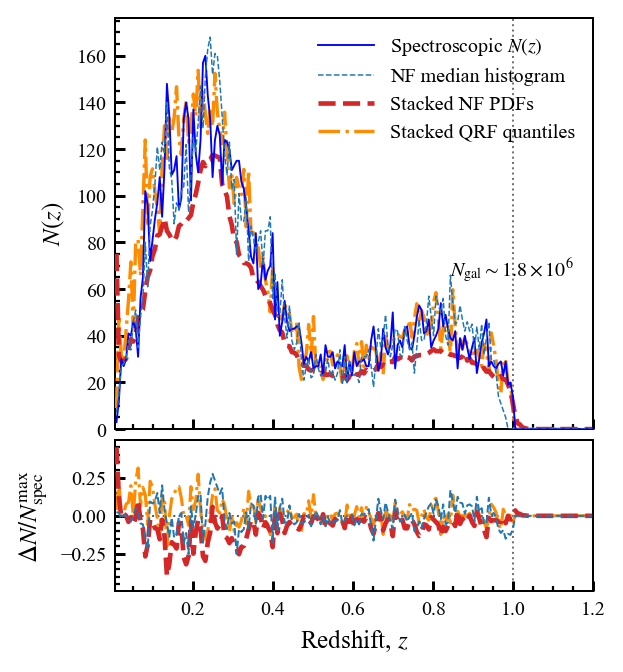

In [110]:

# ============================================================
# show the full N(z) with NF,QRF and NF,.comparing with Spec N(z)
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",

    "font.size": 9,
    "axes.labelsize": 10,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    "axes.linewidth": 0.8,

    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,

    "legend.frameon": False,
})

# ============================================================
# Prepare data
# ============================================================

# Convert to numpy arrays
Nz_spec = np.asarray(nspec2, dtype=float)
Nz_nf = np.asarray(out["Nz_good"], dtype=float)
Nz_qrf = np.asarray(QRF[7], dtype=float)

# Bin centres
# Assuming z_edges contains histogram edges
z_centres = 0.5 * (z_edges[:-1] + z_edges[1:])

# Use only the common valid length
n_bin = min(
    len(z_centres),
    len(Nz_spec),
    len(Nz_nf),
    len(Nz_qrf),
)

z_plot = z_centres[:n_bin]
Nz_spec = Nz_spec[:n_bin]
Nz_nf = Nz_nf[:n_bin]
Nz_qrf = Nz_qrf[:n_bin]
Nz_zmedian = np.histogram(z_median, bins=z_edges)[0]
# Remove non-finite values if any
valid = (
    np.isfinite(z_plot)
    & np.isfinite(Nz_spec)
    & np.isfinite(Nz_nf)
    & np.isfinite(Nz_qrf)
)

z_plot = z_plot[valid]
Nz_spec = Nz_spec[valid]
Nz_nf = Nz_nf[valid]
Nz_qrf = Nz_qrf[valid]

# ============================================================
# Residuals
#
# Peak-normalized residual:
#
# Delta N(z) / N_spec,max
#
# This is more stable than dividing by N_spec(z), especially
# near the low-count tails.
# ============================================================

spec_peak = np.nanmax(Nz_spec)

if not np.isfinite(spec_peak) or spec_peak <= 0:
    raise ValueError("The spectroscopic N(z) has no positive finite peak.")

res_nf = (Nz_nf - Nz_spec) / spec_peak
res_qrf = (Nz_qrf - Nz_spec) / spec_peak
res_zmedian = (Nz_zmedian - Nz_spec) / spec_peak
# Symmetric residual range
res_limit = 1.10 * np.nanmax(
    np.abs(np.concatenate([res_nf, res_qrf]))
)

# Optional: prevent a single extreme bin from making the panel too broad
# Uncomment and choose a suitable value if required.
# res_limit = min(res_limit, 0.40)

# ============================================================
# Figure
# ============================================================

fig, (ax, ax_res) = plt.subplots(
    2,
    1,
    figsize=(3.32, 3.75),   # MNRAS single-column width
    dpi=180,
    sharex=True,
    gridspec_kw={
        "height_ratios": [3.0, 1.1],
        "hspace": 0.04,
    },
)

# ------------------------------------------------------------
# Main panel
# ------------------------------------------------------------

ax.plot(
    z_plot,
    Nz_spec,
    color="blue",
    lw=0.75,
    ls="-",
    label=r"Spectroscopic $N(z)$",
    zorder=5,
)
ax.plot(
    z_plot,
    Nz_zmedian,
    lw=0.60,
    ls="--",
    label=r"NF median histogram",
    zorder=5,
)

ax.plot(
    z_plot,
    Nz_nf,
    color="tab:red",
    lw=1.85,
    ls="--",
    label=r"Stacked NF PDFs",
    zorder=4,
)

ax.plot(
    z_plot,
    Nz_qrf,
    color="darkorange",
    lw=1.35,
    ls="-.",
    label=r"Stacked QRF quantiles",
    zorder=3,
)

ax.set_ylabel(r"$N(z)$")
ax.set_xlim(0.006, 1.2)
ax_res.set_xlim(0.006, 1.2)
ax.set_ylim(bottom=0)

ax.legend(
    loc="upper right",
    handlelength=2.8,
    borderaxespad=0.5,
)

ax.text(
    0.96,
    0.35,
    r"$N_{\rm gal}\sim1.8\times10^{6}$",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=8,
)

# ------------------------------------------------------------
# Residual panel
# ------------------------------------------------------------

ax_res.axhline(
    0.0,
    color="0.35",
    lw=0.8,
    ls=":",
    zorder=1,
)

ax_res.plot(
    z_plot,
    res_nf,
    color="tab:red",
    lw=1.85,
    ls="--",
    label=r"NF $-$ spec-$z$",
    zorder=3,
)
ax_res.plot(
    z_plot,
    res_zmedian,
    lw=0.80,
    ls="--",
    label=r"NF $z_{{\rm median}}$ ",
    zorder=3,
)
ax_res.plot(
    z_plot,
    res_qrf,
    color="darkorange",
    lw=1.25,
    ls="-.",
    label=r"QRF $-$ spec-$z$",
    zorder=2,
)

ax_res.set_xlabel(r"Redshift, $z$")
ax_res.set_ylabel(
    r"$\Delta N/N_{\rm spec}^{\rm max}$"
)

ax_res.set_ylim(
    -res_limit,
    res_limit,
)

# ============================================================
# Tick formatting
# ============================================================

for axis in (ax, ax_res):
    axis.tick_params(
        which="both",
        direction="in",
        top=False,
        right=False,
    )

    axis.xaxis.set_minor_locator(AutoMinorLocator())
    axis.yaxis.set_minor_locator(AutoMinorLocator())

ax.tick_params(labelbottom=False)

# Optional vertical reference line at the high-z boundary
# Uncomment if z=1.0 is a deliberate model/sample cut.
# for axis in (ax, ax_res):
#     axis.axvline(
#         1.0,
#         color="0.6",
#         lw=0.7,
#         ls=":",
#         zorder=0,
#     )
for axis in (ax, ax_res):
    axis.axvline(
        1.0,
        color="0.45",
        lw=0.8,
        ls=":",
        zorder=1,
    )
fig.subplots_adjust(
    left=0.18,
    right=0.98,
    bottom=0.13,
    top=0.98,
)

# ============================================================
# Save
# ============================================================

fig.savefig(
    "Nz_NF_QRF_residual_MNRAS.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "Nz_NF_QRF_residual_MNRAS.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 12. NF tomographic $N(z)$
Tomographic samples are selected by the NF posterior median in four bins: $(0.006,0.2)$, $(0.2,0.4)$, $(0.4,0.6)$, and $(0.6,1.0)$.


In [111]:
#define 4 photo Mask based on median Z
mask_photo1=(z_median>0.006)&(z_median<0.2)
mask_photo2=(z_median>0.2)&(z_median<0.4)
mask_photo3=(z_median>0.4)&(z_median<0.6)
mask_photo4=(z_median>0.6)&(z_median<1.0)


In [112]:
flow_1=x2_flow[mask_photo1]
flow_2=x2_flow[mask_photo2]
flow_3=x2_flow[mask_photo3]
flow_4=x2_flow[mask_photo4]

In [113]:
#define the 4 tomographic stacking bins
z_edges1=np.linspace(0,0.4,101)
z_edges2=np.linspace(0.1,0.7,101)
z_edges3=np.linspace(0.2,0.8,101)
z_edges4=np.linspace(0.4,1.2,101)
hist_bin1=[]
hist_bin2=[]
hist_bin3=[]
hist_bin4=[]
for i in range(len(zs[mask_photo1])): 
    hist_bin1.append(np.histogram(flow_1[i,:], bins=z_edges1,density=True)[0])
for i in range(len(zs[mask_photo2])): 
    hist_bin2.append(np.histogram(flow_2[i,:], bins=z_edges2,density=True)[0])  
for i in range(len(zs[mask_photo3])): 
    hist_bin3.append(np.histogram(flow_3[i,:], bins=z_edges3,density=True)[0]) 
for i in range(len(zs[mask_photo4])): 
    hist_bin4.append(np.histogram(flow_4[i,:], bins=z_edges4,density=True)[0]) 

In [114]:
#bins1 output
out_1 = pipeline_pdf_to_quantiles_mask_stack(hist_bin1, z_edges1, z95_cut=0.01, z50_cut=0.005, width_bins=3)
zbins1=0.5 * (z_edges1[:-1] + z_edges1[1:])
zphoto=np.histogram(z_median[mask_photo1],bins=z_edges1)[0]
zspec_dist_1=np.histogram(zs[mask_photo1],bins=z_edges1)[0]
npred=zphoto
nspec=zspec_dist
zbins2=zbins1
npred2=out_1['Nz_good']
nspec2=zspec_dist_1
compare_nz(zbins2, npred2, nspec2, use_counts_for_chi2=True)

{'mean_pred': 0.12700283354407202,
 'mean_spec': 0.1286138455382153,
 'delta_mean': -0.001611011994143291,
 'rel_delta_mean': -0.0014274253328648728,
 'sigma_pred': 0.053818435969680514,
 'sigma_spec': 0.05227537498966292,
 'delta_sigma': 0.0015430609800175937,
 'rel_delta_sigma': 0.029517932302211565,
 'rmse': 7.89257047807622,
 'chi2': 21705443268545.664,
 'wasserstein_w1': 0.002548679141034422,
 'js_divergence': 0.010758908941987664,
 'overlap': 0.9021648930026667}

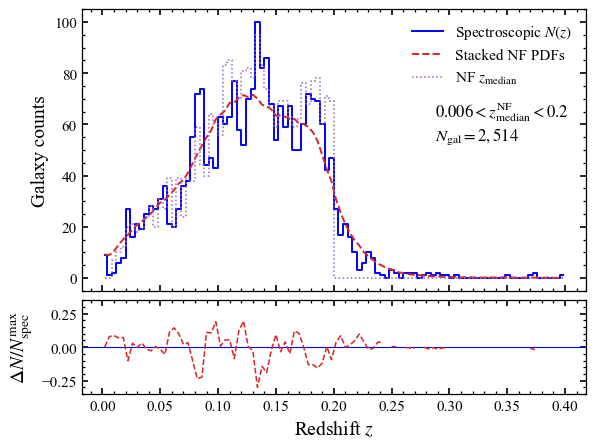

In [115]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})
z = np.asarray(zbins1)
nz_nf = np.asarray(out_1["Nz_good"])
nz_spec = np.asarray(zspec_dist_1)
norm = np.max(nz_spec)
# Convert bin centres to edges
dz = np.median(np.diff(z))
z_edges = np.r_[z - dz / 2, z[-1] + dz / 2]

nz_median, _ = np.histogram(
    z_median[mask_photo1],
    bins=z_edges
)

# Residual relative to spectroscopic N(z)
res_nf = np.divide(
    nz_nf - nz_spec,
    norm,
    out=np.full_like(nz_spec, np.nan, dtype=float),
    where=nz_spec > 0,
)

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(6.5, 5),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05}
)

ax.step(
    z, nz_spec,
    where="mid",
    color="blue",
    lw=1.4,
    label=r"Spectroscopic $N(z)$"
)

ax.plot(
    z, nz_nf,
    color="tab:red",
    ls="--",
    lw=1.4,
    label="Stacked NF PDFs"
)

ax.step(
    z, nz_median,
    where="mid",
    color="tab:purple",
    ls=":",
    lw=1.1,
    label=r"NF $z_{\rm median}$"
)

ax.text(
    0.70, 0.68,
    rf"$0.006<z_{{\rm median}}^{{\rm NF}}<0.2$"
    "\n"
    rf"$N_{{\rm gal}}={np.sum(mask_photo1):,}$",
    transform=ax.transAxes,
    va="top",
    fontsize=12
)

ax.set_ylabel("Galaxy counts")
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

axr.axhline(0, color="blue", lw=0.8)
axr.plot(z, res_nf, color="tab:red", ls="--", lw=1.1)

axr.set_xlabel(r"Redshift $z$")
axr.set_ylabel(r"$\Delta N/N_{\rm spec}^{\rm max}$")
axr.set_ylim(-0.35, 0.35)
axr.xaxis.set_minor_locator(AutoMinorLocator())
axr.yaxis.set_minor_locator(AutoMinorLocator())

plt.savefig(
    "NF_tomographic_Nz_0.006_0.2.pdf",
    bbox_inches="tight"
)
plt.show()

In [116]:
#bins2 output
out_2 = pipeline_pdf_to_quantiles_mask_stack(hist_bin2, z_edges2, z95_cut=0.01, z50_cut=0.005, width_bins=3)
zbins1=0.5 * (z_edges2[:-1] + z_edges2[1:])
zphoto=np.histogram(z_median[mask_photo2],bins=z_edges2)[0]
zspec_dist_1=np.histogram(zs[mask_photo2],bins=z_edges2)[0]
npred=zphoto
nspec=zspec_dist
zbins2=zbins1
npred2=out_2['Nz_good']
nspec2=zspec_dist_1
compare_nz(zbins2, npred2, nspec2, use_counts_for_chi2=True)

{'mean_pred': 0.28840480714046185,
 'mean_spec': 0.2887852494577007,
 'delta_mean': -0.00038044231723882715,
 'rel_delta_mean': -0.00029519449993620813,
 'sigma_pred': 0.07068134443800793,
 'sigma_spec': 0.07127942539920941,
 'delta_sigma': -0.0005980809612014804,
 'rel_delta_sigma': -0.008390653513995835,
 'rmse': 8.892406882019198,
 'chi2': 17378978759122.883,
 'wasserstein_w1': 0.0023354082107522093,
 'js_divergence': 0.0056887820776708,
 'overlap': 0.9259091828280139}

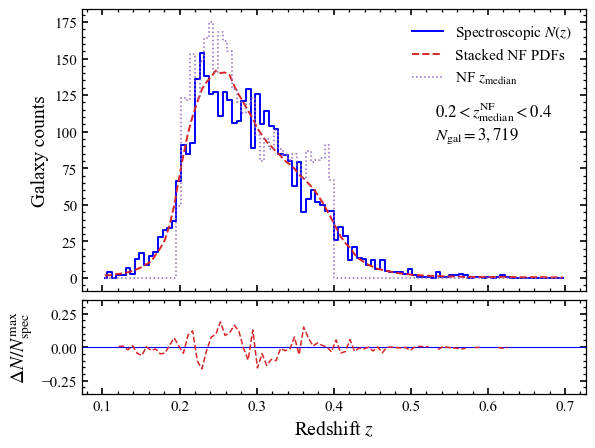

In [117]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})
z = np.asarray(zbins1)
nz_nf = np.asarray(out_2["Nz_good"])
nz_spec = np.asarray(zspec_dist_1)
norm = np.max(nz_spec)
# Convert bin centres to edges
dz = np.median(np.diff(z))
z_edges = np.r_[z - dz / 2, z[-1] + dz / 2]

nz_median, _ = np.histogram(
    z_median[mask_photo2],
    bins=z_edges
)

# Residual relative to spectroscopic N(z)
res_nf = np.divide(
    nz_nf - nz_spec,
    norm,
    out=np.full_like(nz_spec, np.nan, dtype=float),
    where=nz_spec > 0,
)

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(6.5, 5),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05}
)

ax.step(
    z, nz_spec,
    where="mid",
    color="blue",
    lw=1.4,
    label=r"Spectroscopic $N(z)$"
)

ax.plot(
    z, nz_nf,
    color="tab:red",
    ls="--",
    lw=1.4,
    label="Stacked NF PDFs"
)

ax.step(
    z, nz_median,
    where="mid",
    color="tab:purple",
    ls=":",
    lw=1.1,
    label=r"NF $z_{\rm median}$"
)

ax.text(
    0.70, 0.68,
    rf"$0.2<z_{{\rm median}}^{{\rm NF}}<0.4$"
    "\n"
    rf"$N_{{\rm gal}}={np.sum(mask_photo2):,}$",
    transform=ax.transAxes,
    va="top",
    fontsize=12
)

ax.set_ylabel("Galaxy counts")
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

axr.axhline(0, color="blue", lw=0.8)
axr.plot(z, res_nf, color="tab:red", ls="--", lw=1.1)

axr.set_xlabel(r"Redshift $z$")
axr.set_ylabel(r"$\Delta N/N_{\rm spec}^{\rm max}$")
axr.set_ylim(-0.35, 0.35)
axr.xaxis.set_minor_locator(AutoMinorLocator())
axr.yaxis.set_minor_locator(AutoMinorLocator())

plt.savefig(
    "NF_tomographic_Nz_0.2_0.4.pdf",
    bbox_inches="tight"
)
plt.show()

In [118]:
#bins3 output
out_3 = pipeline_pdf_to_quantiles_mask_stack(hist_bin3, z_edges3, z95_cut=0.01, z50_cut=0.005, width_bins=3)
zbins1=0.5 * (z_edges3[:-1] + z_edges3[1:])
zphoto=np.histogram(z_median[mask_photo3],bins=z_edges3)[0]
zspec_dist_1=np.histogram(zs[mask_photo3],bins=z_edges3)[0]
npred=zphoto
nspec=zspec_dist
zbins2=zbins1
npred2=out_3['Nz_good']
nspec2=zspec_dist_1
compare_nz(zbins2, npred2, nspec2, use_counts_for_chi2=True)

{'mean_pred': 0.48319907718669725,
 'mean_spec': 0.4824419889502763,
 'delta_mean': 0.0007570882364209552,
 'rel_delta_mean': 0.0005107034488122215,
 'sigma_pred': 0.08218857121817143,
 'sigma_spec': 0.07976781364235609,
 'delta_sigma': 0.0024207575758153355,
 'rel_delta_sigma': 0.030347548281427786,
 'rmse': 2.874204843558657,
 'chi2': 21318447686824.09,
 'wasserstein_w1': 0.002583555475959675,
 'js_divergence': 0.011893594454541537,
 'overlap': 0.9117082012963635}

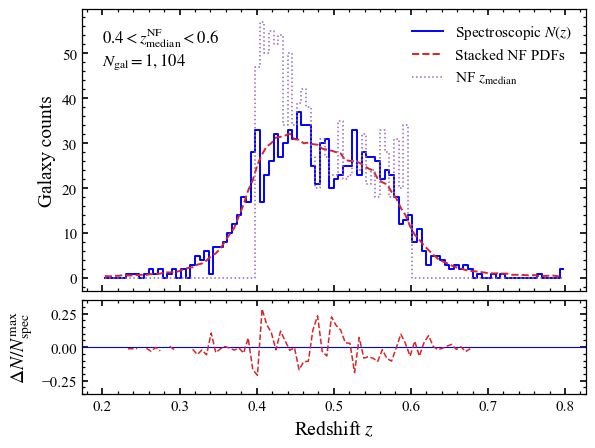

In [119]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})
z = np.asarray(zbins1)
nz_nf = np.asarray(out_3["Nz_good"])
nz_spec = np.asarray(zspec_dist_1)
norm = np.max(nz_spec)
# Convert bin centres to edges
dz = np.median(np.diff(z))
z_edges = np.r_[z - dz / 2, z[-1] + dz / 2]

nz_median, _ = np.histogram(
    z_median[mask_photo3],
    bins=z_edges
)

# Residual relative to spectroscopic N(z)
res_nf = np.divide(
    nz_nf - nz_spec,
    norm,
    out=np.full_like(nz_spec, np.nan, dtype=float),
    where=nz_spec > 0,
)

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(6.5, 5),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05}
)

ax.step(
    z, nz_spec,
    where="mid",
    color="blue",
    lw=1.4,
    label=r"Spectroscopic $N(z)$"
)

ax.plot(
    z, nz_nf,
    color="tab:red",
    ls="--",
    lw=1.4,
    label="Stacked NF PDFs"
)

ax.step(
    z, nz_median,
    where="mid",
    color="tab:purple",
    ls=":",
    lw=1.1,
    label=r"NF $z_{\rm median}$"
)

ax.text(
    0.04, 0.94,
    rf"$0.4<z_{{\rm median}}^{{\rm NF}}<0.6$"
    "\n"
    rf"$N_{{\rm gal}}={np.sum(mask_photo3):,}$",
    transform=ax.transAxes,
    va="top",
    fontsize=12
)

ax.set_ylabel("Galaxy counts")
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

axr.axhline(0, color="blue", lw=0.8)
axr.plot(z, res_nf, color="tab:red", ls="--", lw=1.1)

axr.set_xlabel(r"Redshift $z$")
axr.set_ylabel(r"$\Delta N/N_{\rm spec}^{\rm max}$")
axr.set_ylim(-0.35, 0.35)
axr.xaxis.set_minor_locator(AutoMinorLocator())
axr.yaxis.set_minor_locator(AutoMinorLocator())

plt.savefig(
    "NF_tomographic_Nz_0.4_0.6.pdf",
    bbox_inches="tight"
)
plt.show()

In [120]:
#bins4 output
out_4 = pipeline_pdf_to_quantiles_mask_stack(hist_bin4, z_edges4, z95_cut=0.01, z50_cut=0.005, width_bins=3)
zbins1=0.5 * (z_edges4[:-1] + z_edges4[1:])
zphoto=np.histogram(z_median[mask_photo4],bins=z_edges4)[0]
zspec_dist_1=np.histogram(zs[mask_photo4],bins=z_edges4)[0]
npred=zphoto
nspec=zspec_dist
zbins2=zbins1
npred2=out_4['Nz_good']
nspec2=zspec_dist_1
compare_nz(zbins2, npred2, nspec2, use_counts_for_chi2=True)

{'mean_pred': 0.7930636266265093,
 'mean_spec': 0.7912776831345827,
 'delta_mean': 0.0017859434919266226,
 'rel_delta_mean': 0.0009970221304836302,
 'sigma_pred': 0.11573550797967676,
 'sigma_spec': 0.11279951412935174,
 'delta_sigma': 0.0029359938503250166,
 'rel_delta_sigma': 0.026028426389835282,
 'rmse': 5.442256406870156,
 'chi2': 135381668305985.38,
 'wasserstein_w1': 0.003468951318985792,
 'js_divergence': 0.0072838692924402,
 'overlap': 0.9284370051583574}

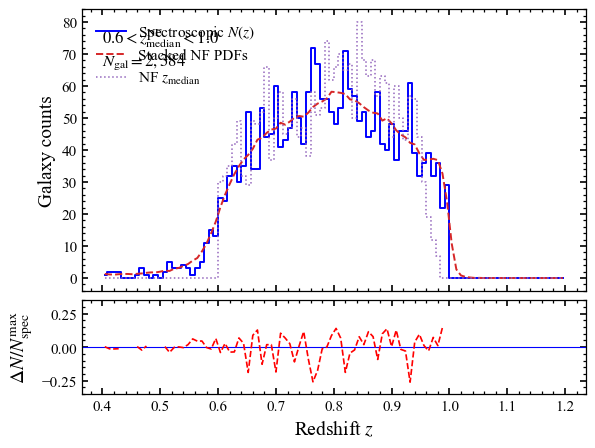

In [121]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})
z = np.asarray(zbins1)
nz_nf = np.asarray(out_4["Nz_good"])
nz_spec = np.asarray(zspec_dist_1)
norm = np.max(nz_spec)
# Convert bin centres to edges
dz = np.median(np.diff(z))
z_edges = np.r_[z - dz / 2, z[-1] + dz / 2]

nz_median, _ = np.histogram(
    z_median[mask_photo4],
    bins=z_edges
)

# Residual relative to spectroscopic N(z)
res_nf = np.divide(
    nz_nf - nz_spec,
    norm,
    out=np.full_like(nz_spec, np.nan, dtype=float),
    where=nz_spec > 0,
)

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(6.5, 5),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05}
)

ax.step(
    z, nz_spec,
    where="mid",
    color="blue",
    lw=1.4,
    label=r"Spectroscopic $N(z)$"
)

ax.plot(
    z, nz_nf,
    color="tab:red",
    ls="--",
    lw=1.4,
    label="Stacked NF PDFs"
)

ax.step(
    z, nz_median,
    where="mid",
    color="tab:purple",
    ls=":",
    lw=1.1,
    label=r"NF $z_{\rm median}$"
)

ax.text(
    0.04, 0.94,
    rf"$0.6<z_{{\rm median}}^{{\rm NF}}<1.0$"
    "\n"
    rf"$N_{{\rm gal}}={np.sum(mask_photo4):,}$",
    transform=ax.transAxes,
    va="top",
    fontsize=12
)

ax.set_ylabel("Galaxy counts")
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

axr.axhline(0, color="blue", lw=0.8)
res_mask = z < 0.995

axr.plot(
    z[res_mask],
    res_nf[res_mask],
    color="red",
    ls="--",
    lw=1.2
)
axr.set_xlabel(r"Redshift $z$")
axr.set_ylabel(r"$\Delta N/N_{\rm spec}^{\rm max}$")
axr.set_ylim(-0.35, 0.35)
axr.xaxis.set_minor_locator(AutoMinorLocator())
axr.yaxis.set_minor_locator(AutoMinorLocator())

plt.savefig(
    "NF_tomographic_Nz_0.6_1.0.pdf",
    bbox_inches="tight"
)
plt.show()

## 13. QRF tomographic $N(z)$
Reconstruct the stacked QRF quantile distributions for the same four median-selected tomographic bins.


In [122]:
def reconstruct_qrf_tomographic_nz(
    y_pred_q,
    z_edges_list,
    tomographic_edges=(0.006, 0.2, 0.4, 0.6, 1.0),
    quantile_levels=None,
    y_test=None,
    chunk_size=100_000,
    renormalize_within_range=False,
):
    """
    Reconstruct four tomographic QRF N(z) distributions.

    Parameters
    ----------
    y_pred_q : ndarray or np.memmap
        QRF quantile predictions with shape
        (N_galaxy, N_quantile).

        For example, if the quantiles are 0.01, ..., 0.99,
        the array has shape (N_galaxy, 99).

    z_edges_list : list of ndarray
        One histogram-edge array for each tomographic bin.

    tomographic_edges : array-like
        Selection boundaries based on the QRF posterior median.

    quantile_levels : array-like, optional
        Quantile levels corresponding to the columns of y_pred_q.
        Default is np.linspace(0.01, 0.99, N_quantile).

    y_test : ndarray, optional
        Spectroscopic redshifts. If supplied, the function also
        returns the corresponding spectroscopic N(z) for each
        QRF-selected tomographic sample.

    chunk_size : int
        Number of galaxies processed at one time.

    renormalize_within_range : bool
        False:
            Every quantile has weight 1/N_quantile. Probability mass
            outside the specified histogram range is not redistributed.
            This is the more physically faithful choice.

        True:
            Each galaxy is renormalized to unit probability within the
            specified histogram range, reproducing your earlier stacking
            convention.

    Returns
    -------
    result : dict
        Dictionary containing the four tomographic N(z) results.
    """

    y_pred_q = np.asarray(y_pred_q)

    if y_pred_q.ndim != 2:
        raise ValueError(
            "y_pred_q must have shape (N_galaxy, N_quantile)."
        )

    n_galaxy, n_quantile = y_pred_q.shape

    tomographic_edges = np.asarray(
        tomographic_edges,
        dtype=np.float32,
    )

    if len(z_edges_list) != len(tomographic_edges) - 1:
        raise ValueError(
            "The number of z_edges arrays must equal the number "
            "of tomographic bins."
        )

    if np.any(np.diff(tomographic_edges) <= 0):
        raise ValueError(
            "tomographic_edges must be strictly increasing."
        )

    if quantile_levels is None:
        quantile_levels = np.linspace(
            0.01,
            0.99,
            n_quantile,
            dtype=np.float32,
        )
    else:
        quantile_levels = np.asarray(
            quantile_levels,
            dtype=np.float32,
        )

    if quantile_levels.size != n_quantile:
        raise ValueError(
            "quantile_levels must match the second dimension "
            "of y_pred_q."
        )

    # Find the column corresponding to q = 0.5
    median_index = int(
        np.argmin(np.abs(quantile_levels - 0.5))
    )

    if not np.isclose(
        quantile_levels[median_index],
        0.5,
        atol=1e-6,
    ):
        raise ValueError(
            "The supplied quantile grid does not contain q=0.5."
        )

    if y_test is not None:
        y_test = np.asarray(y_test).reshape(-1)

        if y_test.size != n_galaxy:
            raise ValueError(
                "y_test and y_pred_q contain different "
                "numbers of galaxies."
            )

    # --------------------------------------------------------
    # Initialise outputs
    # --------------------------------------------------------
    bins_output = []

    for bin_index, z_edges in enumerate(z_edges_list):

        z_edges = np.asarray(
            z_edges,
            dtype=np.float32,
        )

        if np.any(np.diff(z_edges) <= 0):
            raise ValueError(
                f"z_edges_list[{bin_index}] is not increasing."
            )

        n_zbin = len(z_edges) - 1

        bins_output.append({
            "bin_index": bin_index,
            "selection_low": float(
                tomographic_edges[bin_index]
            ),
            "selection_high": float(
                tomographic_edges[bin_index + 1]
            ),
            "z_edges": z_edges,
            "z_centres": (
                0.5 * (z_edges[:-1] + z_edges[1:])
            ).astype(np.float32),
            "nqrf": np.zeros(
                n_zbin,
                dtype=np.float64,
            ),
            "nmedian": np.zeros(
                n_zbin,
                dtype=np.int64,
            ),
            "nspec": (
                np.zeros(n_zbin, dtype=np.int64)
                if y_test is not None
                else None
            ),
            "n_gal": 0,
            "n_valid_pdf": 0,
        })

    # --------------------------------------------------------
    # Process all galaxies in chunks
    # --------------------------------------------------------
    for start in range(0, n_galaxy, chunk_size):

        stop = min(
            start + chunk_size,
            n_galaxy,
        )

        print(
            f"Processing galaxies "
            f"{start:,}--{stop:,} / {n_galaxy:,}"
        )

        # Only this chunk is loaded into memory
        q_chunk = np.asarray(
            y_pred_q[start:stop],
            dtype=np.float32,
        )

        median_chunk = q_chunk[:, median_index]

        if y_test is not None:
            y_test_chunk = y_test[start:stop]

        for bin_index, output in enumerate(bins_output):

            selection_low = output["selection_low"]
            selection_high = output["selection_high"]

            # Final bin includes its upper edge
            if bin_index == len(bins_output) - 1:
                tomo_mask = (
                    (median_chunk >= selection_low)
                    & (median_chunk <= selection_high)
                )
            else:
                tomo_mask = (
                    (median_chunk >= selection_low)
                    & (median_chunk < selection_high)
                )

            n_selected = int(np.count_nonzero(tomo_mask))

            if n_selected == 0:
                continue

            output["n_gal"] += n_selected

            selected_median = median_chunk[tomo_mask]
            selected_quantiles = q_chunk[tomo_mask]

            z_edges = output["z_edges"]
            n_zbin = len(z_edges) - 1

            # Median histogram
            output["nmedian"] += np.histogram(
                selected_median,
                bins=z_edges,
            )[0]

            # Spectroscopic histogram for the same selected galaxies
            if y_test is not None:
                output["nspec"] += np.histogram(
                    y_test_chunk[tomo_mask],
                    bins=z_edges,
                )[0]

            # Quantiles lying inside the adopted histogram range
            valid = (
                (selected_quantiles >= z_edges[0])
                & (selected_quantiles <= z_edges[-1])
                & np.isfinite(selected_quantiles)
            )

            n_valid_per_galaxy = valid.sum(axis=1)

            good_pdf = n_valid_per_galaxy > 0

            output["n_valid_pdf"] += int(
                np.count_nonzero(good_pdf)
            )

            if not np.any(good_pdf):
                continue

            selected_quantiles = selected_quantiles[good_pdf]
            valid = valid[good_pdf]
            n_valid_per_galaxy = n_valid_per_galaxy[good_pdf]

            # Find histogram-bin indices
            quantile_bin_index = (
                np.searchsorted(
                    z_edges,
                    selected_quantiles,
                    side="right",
                )
                - 1
            )

            # z == z_edges[-1] belongs to the final histogram bin
            quantile_bin_index = np.clip(
                quantile_bin_index,
                0,
                n_zbin - 1,
            )

            if renormalize_within_range:

                # Each galaxy contributes total weight 1 inside
                # the displayed redshift range.
                weights = (
                    valid.astype(np.float64)
                    / n_valid_per_galaxy[:, None]
                )

            else:

                # Every predicted quantile has equal probability
                # weight 1/N_quantile.
                weights = (
                    valid.astype(np.float64)
                    / float(n_quantile)
                )

            output["nqrf"] += np.bincount(
                quantile_bin_index[valid],
                weights=weights[valid],
                minlength=n_zbin,
            )

        del q_chunk
        del median_chunk

    result = {
        "selection_variable": "QRF posterior median",
        "quantile_levels": quantile_levels,
        "median_index": median_index,
        "tomographic_edges": tomographic_edges,
        "renormalize_within_range": renormalize_within_range,
        "bins": bins_output,
    }

    return result

In [123]:
z_edges1 = np.linspace(
    0.0,
    0.4,
    101,
    dtype=np.float32,
)

z_edges2 = np.linspace(
    0.1,
    0.7,
    101,
    dtype=np.float32,
)

z_edges3 = np.linspace(
    0.2,
    0.8,
    101,
    dtype=np.float32,
)

z_edges4 = np.linspace(
    0.4,
    1.2,
    101,
    dtype=np.float32,
)

z_edges_list = [
    z_edges1,
    z_edges2,
    z_edges3,
    z_edges4,
]

In [124]:
tomography_qrf = reconstruct_qrf_tomographic_nz(
    y_pred_q=y_pred_q,
    y_test=QRF[0],
    z_edges_list=z_edges_list,
    tomographic_edges=[
        0.006,
        0.2,
        0.4,
        0.6,
        1.0,
    ],
    quantile_levels=np.linspace(
        0.01,
        0.99,
        99,
    ),
    chunk_size=100_000,
    renormalize_within_range=False,
)

Processing galaxies 0--12,568 / 12,568


In [125]:
bin1 = tomography_qrf["bins"][0]
bin2 = tomography_qrf["bins"][1]
bin3 = tomography_qrf["bins"][2]
bin4 = tomography_qrf["bins"][3]

# QRF stacked N(z)
nqrf1 = bin1["nqrf"]
nqrf2 = bin2["nqrf"]
nqrf3 = bin3["nqrf"]
nqrf4 = bin4["nqrf"]

# Histogram centres
z_centres1 = bin1["z_centres"]
z_centres2 = bin2["z_centres"]
z_centres3 = bin3["z_centres"]
z_centres4 = bin4["z_centres"]

# QRF median histograms
nmedian1 = bin1["nmedian"]
nmedian2 = bin2["nmedian"]
nmedian3 = bin3["nmedian"]
nmedian4 = bin4["nmedian"]

# Spectroscopic references, provided y_test=zs was passed
nspec1 = bin1["nspec"]
nspec2 = bin2["nspec"]
nspec3 = bin3["nspec"]
nspec4 = bin4["nspec"]

In [126]:
for result_bin in tomography_qrf["bins"]:
    print(
        f"Bin {result_bin['bin_index'] + 1}: "
        f"{result_bin['selection_low']:.3f} <= z_median "
        f"< {result_bin['selection_high']:.3f}, "
        f"N_gal = {result_bin['n_gal']:,}, "
        f"N_valid = {result_bin['n_valid_pdf']:,}"
    )

Bin 1: 0.006 <= z_median < 0.200, N_gal = 2,531, N_valid = 2,531
Bin 2: 0.200 <= z_median < 0.400, N_gal = 3,881, N_valid = 3,881
Bin 3: 0.400 <= z_median < 0.600, N_gal = 932, N_valid = 932
Bin 4: 0.600 <= z_median < 1.000, N_gal = 2,451, N_valid = 2,451


In [127]:
compare_nz(z_centres1,nqrf1,nspec1)

{'mean_pred': 0.13714453484775896,
 'mean_spec': 0.13274840633489418,
 'delta_mean': 0.004396128512864778,
 'rel_delta_mean': 0.0038809399230044675,
 'sigma_pred': 0.06327801316240189,
 'sigma_spec': 0.057671265304721366,
 'delta_sigma': 0.005606747857680526,
 'rel_delta_sigma': 0.09721908871004985,
 'rmse': 8.954079702119376,
 'chi2': 39892051831726.58,
 'wasserstein_w1': 0.005110664347202348,
 'js_divergence': 0.014485026190336129,
 'overlap': 0.8827421465295114}

In [128]:
compare_nz(z_centres2,nqrf2,nspec2)

{'mean_pred': 0.2884178188966676,
 'mean_spec': 0.29225781402530393,
 'delta_mean': -0.0038399951286363088,
 'rel_delta_mean': -0.0029715394923207775,
 'sigma_pred': 0.08408089447498944,
 'sigma_spec': 0.07935085576280311,
 'delta_sigma': 0.00473003871218633,
 'rel_delta_sigma': 0.059609170773475204,
 'rmse': 9.6973674686933,
 'chi2': 6506887052540.895,
 'wasserstein_w1': 0.0052851659894401,
 'js_divergence': 0.006459664351646384,
 'overlap': 0.9197855734838543}

In [129]:
compare_nz(z_centres3,nqrf3,nspec3)

{'mean_pred': 0.4872086729934452,
 'mean_spec': 0.49317692335823465,
 'delta_mean': -0.005968250364789429,
 'rel_delta_mean': -0.003997014869052835,
 'sigma_pred': 0.10459399024096916,
 'sigma_spec': 0.08735589000916635,
 'delta_sigma': 0.017238100231802805,
 'rel_delta_sigma': 0.19733185970624295,
 'rmse': 4.6175908977970375,
 'chi2': 111976941128691.95,
 'wasserstein_w1': 0.015486045248975233,
 'js_divergence': 0.03437619909955328,
 'overlap': 0.8342461907812235}

In [130]:
compare_nz(z_centres4,nqrf4,nspec4)

{'mean_pred': 0.7789651533976457,
 'mean_spec': 0.7869798492252731,
 'delta_mean': -0.008014695827627372,
 'rel_delta_mean': -0.004485051037985717,
 'sigma_pred': 0.12096272529746481,
 'sigma_spec': 0.11641850368556571,
 'delta_sigma': 0.004544221611899102,
 'rel_delta_sigma': 0.039033499555814366,
 'rmse': 6.517758541904577,
 'chi2': 40845832058128.97,
 'wasserstein_w1': 0.008014702484679132,
 'js_divergence': 0.00808594162550779,
 'overlap': 0.9202366924335768}

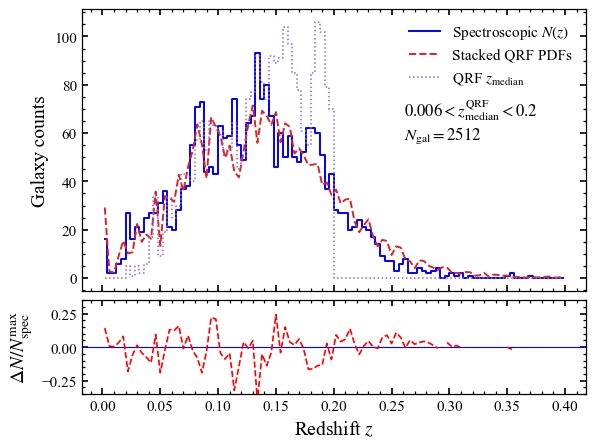

In [131]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})
z = np.asarray(z_centres1)
nz_qrf = np.asarray(nqrf1)
nz_spec = np.asarray(nspec1)
norm = np.max(nz_spec)
# Convert bin centres to edges
dz = np.median(np.diff(z))
z_edges = np.r_[z - dz / 2, z[-1] + dz / 2]

nz_median=np.asarray(nmedian1)

# Residual relative to spectroscopic N(z)
res_qrf = np.divide(
    nz_qrf - nz_spec,
    norm,
    out=np.full_like(nz_spec, np.nan, dtype=float),
    where=nz_spec > 0,
)

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(6.5, 5),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05}
)

ax.step(
    z, nz_spec,
    where="mid",
    color="blue",
    lw=1.4,
    label=r"Spectroscopic $N(z)$"
)

ax.plot(
    z, nz_qrf,
    color="tab:red",
    ls="--",
    lw=1.4,
    label="Stacked QRF PDFs"
)

ax.step(
    z, nz_median,
    where="mid",
    color="tab:purple",
    ls=":",
    lw=1.1,
    label=r"QRF $z_{\rm median}$"
)

ax.text(
    0.64, 0.69,
    rf"$0.006<z_{{\rm median}}^{{\rm QRF}}<0.2$"
    "\n"
    rf"$N_{{\rm gal}}={np.sum(nspec1)}$",
    transform=ax.transAxes,
    va="top",
    fontsize=12
)

ax.set_ylabel("Galaxy counts")
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

axr.axhline(0, color="blue", lw=0.8)
res_mask = z < 0.995

axr.plot(
    z[res_mask],
    res_qrf[res_mask],
    color="red",
    ls="--",
    lw=1.2
)
axr.set_xlabel(r"Redshift $z$")
axr.set_ylabel(r"$\Delta N/N_{\rm spec}^{\rm max}$")
axr.set_ylim(-0.35, 0.35)

axr.xaxis.set_minor_locator(AutoMinorLocator())
axr.yaxis.set_minor_locator(AutoMinorLocator())

plt.savefig(
    "QRF_tomographic_Nz_0.006_0.2.pdf",
    bbox_inches="tight"
)
plt.show()

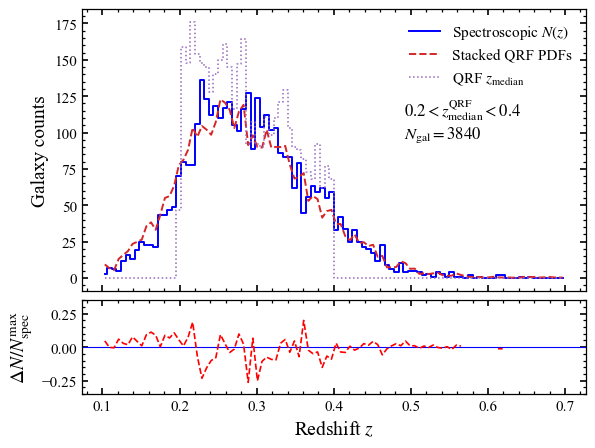

In [132]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})
z = np.asarray(z_centres2)
nz_qrf = np.asarray(nqrf2)
nz_spec = np.asarray(nspec2)
norm = np.max(nz_spec)
# Convert bin centres to edges
dz = np.median(np.diff(z))
z_edges = np.r_[z - dz / 2, z[-1] + dz / 2]

nz_median=np.asarray(nmedian2)

# Residual relative to spectroscopic N(z)
res_qrf = np.divide(
    nz_qrf - nz_spec,
    norm,
    out=np.full_like(nz_spec, np.nan, dtype=float),
    where=nz_spec > 0,
)

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(6.5, 5),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05}
)

ax.step(
    z, nz_spec,
    where="mid",
    color="blue",
    lw=1.4,
    label=r"Spectroscopic $N(z)$"
)

ax.plot(
    z, nz_qrf,
    color="tab:red",
    ls="--",
    lw=1.4,
    label="Stacked QRF PDFs"
)

ax.step(
    z, nz_median,
    where="mid",
    color="tab:purple",
    ls=":",
    lw=1.1,
    label=r"QRF $z_{\rm median}$"
)

ax.text(
    0.64, 0.69,
    rf"$0.2<z_{{\rm median}}^{{\rm QRF}}<0.4$"
    "\n"
    rf"$N_{{\rm gal}}={np.sum(nspec2)}$",
    transform=ax.transAxes,
    va="top",
    fontsize=12
)

ax.set_ylabel("Galaxy counts")
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

axr.axhline(0, color="blue", lw=0.8)
res_mask = z < 0.995

axr.plot(
    z[res_mask],
    res_qrf[res_mask],
    color="red",
    ls="--",
    lw=1.2
)
axr.set_xlabel(r"Redshift $z$")
axr.set_ylabel(r"$\Delta N/N_{\rm spec}^{\rm max}$")
axr.set_ylim(-0.35, 0.35)

axr.xaxis.set_minor_locator(AutoMinorLocator())
axr.yaxis.set_minor_locator(AutoMinorLocator())

plt.savefig(
    "QRF_tomographic_Nz_0.2_0.4.pdf",
    bbox_inches="tight"
)
plt.show()

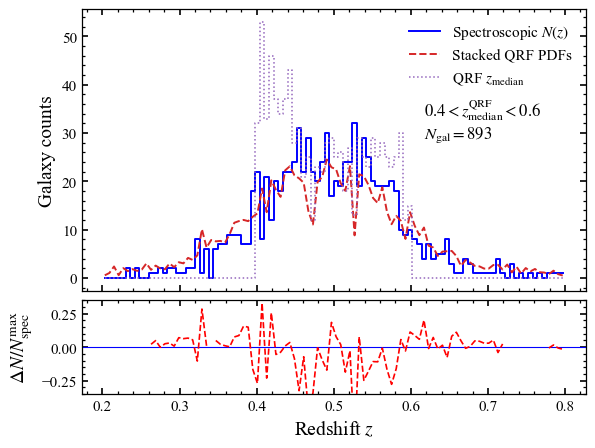

In [133]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})
z = np.asarray(z_centres3)
nz_qrf = np.asarray(nqrf3)
nz_spec = np.asarray(nspec3)
norm = np.max(nz_spec)
# Convert bin centres to edges
dz = np.median(np.diff(z))
z_edges = np.r_[z - dz / 2, z[-1] + dz / 2]

nz_median=np.asarray(nmedian3)

# Residual relative to spectroscopic N(z)
res_qrf = np.divide(
    nz_qrf - nz_spec,
    norm,
    out=np.full_like(nz_spec, np.nan, dtype=float),
    where=nz_spec > 0,
)

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(6.5, 5),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05}
)

ax.step(
    z, nz_spec,
    where="mid",
    color="blue",
    lw=1.4,
    label=r"Spectroscopic $N(z)$"
)

ax.plot(
    z, nz_qrf,
    color="tab:red",
    ls="--",
    lw=1.4,
    label="Stacked QRF PDFs"
)

ax.step(
    z, nz_median,
    where="mid",
    color="tab:purple",
    ls=":",
    lw=1.1,
    label=r"QRF $z_{\rm median}$"
)

ax.text(
    0.68, 0.69,
    rf"$0.4<z_{{\rm median}}^{{\rm QRF}}<0.6$"
    "\n"
    rf"$N_{{\rm gal}}={np.sum(nspec3)}$",
    transform=ax.transAxes,
    va="top",
    fontsize=12
)

ax.set_ylabel("Galaxy counts")
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())
axr.axhline(0, color="blue", lw=0.8)

axr.plot(
    z[res_mask],
    res_qrf[res_mask],
    color="red",
    ls="--",
    lw=1.2
)
axr.set_xlabel(r"Redshift $z$")
axr.set_ylabel(r"$\Delta N/N_{\rm spec}^{\rm max}$")
axr.set_ylim(-0.35, 0.35)
axr.xaxis.set_minor_locator(AutoMinorLocator())
axr.yaxis.set_minor_locator(AutoMinorLocator())

plt.savefig(
    "QRF_tomographic_Nz_0.4_0.6.pdf",
    bbox_inches="tight"
)
plt.show()

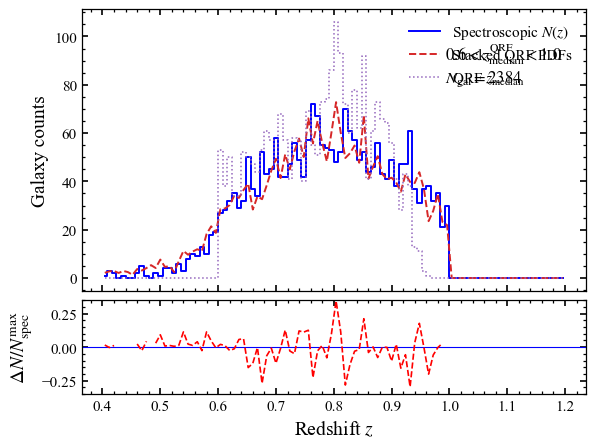

In [134]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})
z = np.asarray(z_centres4)
nz_qrf = np.asarray(nqrf4)
nz_spec = np.asarray(nspec4)
norm = np.max(nz_spec)
# Convert bin centres to edges
dz = np.median(np.diff(z))
z_edges = np.r_[z - dz / 2, z[-1] + dz / 2]

nz_median=np.asarray(nmedian4)

# Residual relative to spectroscopic N(z)
res_qrf = np.divide(
    nz_qrf - nz_spec,
    norm,
    out=np.full_like(nz_spec, np.nan, dtype=float),
    where=nz_spec > 0,
)

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(6.5, 5),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05}
)

ax.step(
    z, nz_spec,
    where="mid",
    color="blue",
    lw=1.4,
    label=r"Spectroscopic $N(z)$"
)

ax.plot(
    z, nz_qrf,
    color="tab:red",
    ls="--",
    lw=1.4,
    label="Stacked QRF PDFs"
)

ax.step(
    z, nz_median,
    where="mid",
    color="tab:purple",
    ls=":",
    lw=1.1,
    label=r"QRF $z_{\rm median}$"
)

ax.text(
    0.72, 0.89,
    rf"$0.6<z_{{\rm median}}^{{\rm QRF}}<1.0$"
    "\n"
    rf"$N_{{\rm gal}}={np.sum(nspec4)}$",
    transform=ax.transAxes,
    va="top",
    fontsize=12
)

ax.set_ylabel("Galaxy counts")
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

axr.axhline(0, color="blue", lw=0.8)
res_mask = z < 0.995

axr.plot(
    z[res_mask],
    res_qrf[res_mask],
    color="red",
    ls="--",
    lw=1.2
)
axr.set_xlabel(r"Redshift $z$")
axr.set_ylabel(r"$\Delta N/N_{\rm spec}^{\rm max}$")
axr.set_ylim(-0.35, 0.35)
axr.xaxis.set_minor_locator(AutoMinorLocator())
axr.yaxis.set_minor_locator(AutoMinorLocator())

plt.savefig(
    "QRF_tomographic_Nz_0.6_1.0.pdf",
    bbox_inches="tight"
)
plt.show()